# Análise comparativa de operadoras — Inteligência de Mercado e Sinistro

**Desafio técnico | PASA — Gerência de Inteligência de Mercado e Sinistro**
**Período analisado:** agosto/2025 a julho/2026 (12 competências) · **Fontes:** Receita, Vidas e Despesa

---

## Resumo executivo para a diretoria


**Mensagem principal.** As duas operadoras **não são comparáveis pelos números brutos**:

- A **Operadora Y** é uma carteira envelhecida e de alta severidade, mas **mais barata que a X em 8 das 10 faixas etárias**.
- A **Operadora X** é uma carteira jovem, com **custo por faixa mais alto** nas idades adultas.
- Em **jan/2026, um bloco de cerca de 10 mil vidas migrou da X para a Y**. Isso distorce a leitura de crescimento e chega à Y sem receita registrada.
- **Não há receita da X**, que é a maior carteira, para avaliar a sustentabilidade financeira dela.

| # | Evidência | Risco | Recomendação |
|---|---|---|---|
| 1 | **Transferência de carteira X → Y em jan/2026.** O plano `340154BC84` da X (PA) cai de 10.110 para 8 vidas e, no mesmo mês, nasce o plano `0F2726E6AC` da Y (PA) com 10.244 vidas e perfil etário 99,0% semelhante. Sem esse bloco, a X **cresce 0,52%** e a Y **encolhe 0,84%** no período. | Ler o +12,42% da Y como expansão comercial. O plano chegou à Y **sem receita na base** (13,6% das vidas da Y a partir de jan/2026), e a X seguiu pagando **R$ 0,95 mi de cauda** de sinistros após a saída. | Confirmar a natureza contratual da operação, definir quem responde pela cauda (IBNR) e obter a receita do plano antes de reportar a sinistralidade da Y. |
| 2 | **Custo per capita líquido:** Y R$ 261,54 × X R$ 124,39 por vida/mês (2,1×). **Com a pirâmide etária da X, a Y custaria R$ 111,15**, menos que a X: a idade explica 109,7% da diferença. O custo médio por item é praticamente igual (X R$ 26,92; Y R$ 26,47). A diferença é de **volume**, não de preço. | Concluir que a Y é "cara" ou "ineficiente" é um erro de leitura. O ponto de atenção da X é o custo por faixa **13% a 53% acima do da Y entre 19 e 53 anos**. | Adotar o **custo per capita padronizado por idade** como KPI comparativo. Na X, investigar frequência de utilização e protocolos nas faixas adultas. |
| 3 | **Concentração etária da Y:** a faixa 59+ reúne 48,51% das vidas e 78,39% da despesa bruta. A internação responde por 56,43% da despesa líquida da Y (X: 45,96%). | Severidade alta e crônica, exposição a eventos de alto custo e pressão estrutural de custo com o envelhecimento da carteira. | Gestão de crônicos e linhas de cuidado 60+, monitoramento de alto custo e de reinternações, e reajuste aderente à pirâmide etária. |
| 4 | **Mix assistencial da Y:** medicamentos 28,26% e pacotes 21,42% da despesa bruta (X: 15,55% e 16,34%). | Exposição a medicamentos de alto custo e a pacotes hospitalares mal precificados. | Auditoria de medicamentos especiais, autorização prévia por protocolo e renegociação de pacotes com a rede. |
| 5 | **Sinistralidade da Y de 34,15% e ROI assistencial de 192,80%**, muito abaixo dos patamares usuais do setor. | Apresentar uma margem que talvez não exista: o descasamento de escopo entre receita e despesa infla o resultado. | Validar o escopo de receita e de despesa (competência, itens e completude) **antes** de usar esses números em precificação, reajuste ou metas. |
| 6 | **Receita da Operadora X ausente** em todas as competências. | A carteira 4,8× maior que a Y fica sem avaliação de sustentabilidade financeira. | Solicitar a receita da X com prioridade. Até lá, sinistralidade e ROI da X ficam **indisponíveis, nunca zero**. |
| 7 | **Qualidade financeira:** 22.345 eventos com coparticipação acima do valor bruto (0,53% na X, 0,11% na Y). Se forem truncados, a sinistralidade da Y passa de 34,15% para 34,24%. | Efeito imaterial, mas indica uma regra de lançamento não documentada. | Auditar a regra de coparticipação e publicar um dicionário de dados com a definição oficial de despesa líquida. |


> Todos os números deste resumo são recalculados e conferidos automaticamente na **seção 8** (`assert`). Se a base mudar, o notebook falha antes de apresentar um número desatualizado.

### Como ler este estudo

Cada achado segue a estrutura **Evidência → Risco → Recomendação**:

- **Evidência:** o número e a tabela que o sustentam.
- **Risco:** o que pode dar errado para a carteira, a precificação ou a gestão de sinistro se o achado for ignorado.
- **Recomendação:** a ação que a diretoria pode tomar com segurança a partir dos dados disponíveis.

### Premissas metodológicas

| Tema | Premissa adotada | Por quê |
|---|---|---|
| Despesa líquida | `valor_bruto − valor_coparticipacao` | Não há coluna pronta nem dicionário de dados; a premissa é explícita e testada por sensibilidade (seção 3). |
| Receita | Tratada como receita líquida de contraprestações | É a única medida de receita disponível. |
| Receita da Operadora X | **Ausente** — nunca imputada como zero | Sinistralidade e ROI da X ficam indisponíveis, e não 0%. |
| Sinistralidade | `Despesa líquida ÷ Receita × 100`, sobre os **totais do período** | Evita a média simples de percentuais mensais. |
| ROI assistencial | `(Receita − Despesa líquida) ÷ Despesa líquida × 100` | Não inclui despesas administrativas, comerciais nem tributos. |
| Custo per capita | `Média mensal da despesa líquida ÷ Média mensal de vidas` | Equivale a Σ despesa ÷ Σ vidas-mês (exposição ponderada). |
| Vidas | Média mensal = exposição média | Vidas não são pessoas únicas ao longo do ano. |

## 0. Configuração, caminhos e contrato de dados

O notebook localiza a raiz do projeto a partir da pasta em que é executado — **não há caminhos absolutos**. Os nomes das fontes respeitam maiúsculas e minúsculas (`Receita.csv`, `Vidas.csv`, `Despesa.csv`), o que garante a execução também em Linux e macOS.

O dicionário `SCHEMA_POWERBI` é o **contrato de dados** com o dashboard: nomes de arquivo e ordem de colunas que o Power BI espera. A exportação (seção 7) só grava arquivos depois de validar esse contrato contra a última versão publicada em `output/`.

In [1]:
from pathlib import Path
import io
import warnings

import matplotlib.pyplot as plt
import matplotlib.ticker as mticker
import numpy as np
import pandas as pd
from IPython.display import Markdown, display

pd.set_option("display.max_columns", 100)
pd.set_option("display.max_rows", 100)
pd.set_option("display.width", 160)
pd.set_option("display.float_format", lambda valor: f"{valor:,.2f}")
warnings.filterwarnings("default")


def localizar_raiz_projeto(inicio: Path | None = None) -> Path:
    """Sobe a árvore de diretórios até encontrar a pasta ``data/`` do projeto."""
    inicio = (inicio or Path.cwd()).resolve()
    for pasta in (inicio, *inicio.parents):
        if (pasta / "data").is_dir():
            return pasta
    raise FileNotFoundError(
        "Pasta 'data/' não encontrada. Execute o notebook a partir da pasta do projeto."
    )


PASTA_RAIZ = localizar_raiz_projeto()
PASTA_DADOS = PASTA_RAIZ / "data"
PASTA_SAIDA = PASTA_RAIZ / "output"

ARQUIVOS_FONTE = {
    "receita": PASTA_DADOS / "Receita.csv",
    "vidas": PASTA_DADOS / "Vidas.csv",
    "despesa": PASTA_DADOS / "Despesa.csv",
}

CHAVES_SEGMENTO = ["data_ref", "Operadora", "faixa_etaria", "uf", "cidade", "Plano"]
CHAVES_MES = ["Operadora", "data_ref"]

# Contrato de dados com o Power BI: arquivo -> colunas na ordem exata.
SCHEMA_POWERBI = {
    "indicadores_mensais.csv": [
        "Operadora", "data_ref", "despesa_bruta", "coparticipacao", "despesa_liquida",
        "registros", "registros_liquidos_negativos", "vidas", "receita",
        "sinistralidade_pct", "roi_pct", "custo_per_capita_mensal",
    ],
    "perfil_carteira_faixa_etaria.csv": [
        "Operadora", "faixa_etaria", "media_mensal_vidas", "participacao_pct",
    ],
    "perfil_despesas_classificacao.csv": [
        "Operadora", "classificacao", "despesa_bruta", "participacao_pct",
    ],
    "qualidade_dados_financeiros.csv": [
        "Operadora", "registros", "ocorrencias", "valor_bruto_nas_ocorrencias",
        "coparticipacao_nas_ocorrencias", "saldo_estimado_nas_ocorrencias",
        "despesa_bruta_total", "coparticipacao_total", "despesa_liquida_estimada_total",
        "registros_liquidos_negativos", "percentual_ocorrencias",
    ],
    "indicadores_periodo.csv": [
        "Operadora", "receita_total", "despesa_liquida_total", "media_despesa_liquida",
        "media_vidas", "meses_com_receita", "meses_analisados",
        "cobertura_receita_completa", "sinistralidade_pct", "roi_pct",
        "custo_per_capita", "status_receita",
    ],
    "perfil_despesas_faixa_etaria.csv": [
        "Operadora", "faixa_etaria", "despesa_bruta_periodo", "media_mensal_vidas",
        "meses_observados", "despesa_bruta_media_mensal", "despesa_bruta_por_vida",
        "participacao_vidas_pct", "participacao_despesa_pct",
    ],
}

# Identidade visual: a cor acompanha a operadora em todos os gráficos.
CORES_OPERADORA = {"Operadora X": "#2a78d6", "Operadora Y": "#eb6834"}
COR_NEUTRA = "#a3a29c"
COR_TEXTO = "#0b0b0b"
COR_TEXTO_SECUNDARIO = "#52514e"
COR_GRADE = "#e4e3df"

plt.rcParams.update({
    "figure.dpi": 110,
    "font.size": 10,
    "axes.edgecolor": COR_GRADE,
    "axes.labelcolor": COR_TEXTO_SECUNDARIO,
    "xtick.color": COR_TEXTO_SECUNDARIO,
    "ytick.color": COR_TEXTO_SECUNDARIO,
    "lines.linewidth": 2,
    "lines.markersize": 5,
    "legend.frameon": False,
})

print(f"Raiz do projeto: .../{PASTA_RAIZ.name}")
for nome, caminho in ARQUIVOS_FONTE.items():
    print(f"  {nome:<8} -> {caminho.relative_to(PASTA_RAIZ)}")

Raiz do projeto: .../teste-pasa
  receita  -> data\Receita.csv
  vidas    -> data\Vidas.csv
  despesa  -> data\Despesa.csv


In [2]:
# Funções utilitárias reutilizadas em todo o notebook.


def dividir_seguro(numerador, denominador):
    """Divide preservando NaN quando o denominador é ausente, zero ou negativo."""
    if np.isscalar(denominador):
        return numerador / denominador if pd.notna(denominador) and denominador > 0 else np.nan
    return numerador / denominador.where(denominador > 0)


def variacao_pct(inicial, final):
    """Variação percentual entre dois valores."""
    return dividir_seguro(final - inicial, inicial) * 100


def para_exibicao(df: pd.DataFrame, casas: int = 2) -> pd.DataFrame:
    """Cópia arredondada apenas para leitura; os cálculos usam os valores íntegros."""
    saida = df.copy()
    numericas = saida.select_dtypes(include="number").columns
    saida[numericas] = saida[numericas].round(casas)
    return saida


def _formato_br(valor: float, casas: int) -> str:
    return f"{valor:,.{casas}f}".replace(",", "_").replace(".", ",").replace("_", ".")


def num(valor: float, casas: int = 0) -> str:
    return _formato_br(valor, casas)


def brl(valor: float, casas: int = 2) -> str:
    return f"R$ {_formato_br(valor, casas)}"


def brl_mi(valor: float, casas: int = 2) -> str:
    return f"R$ {_formato_br(valor / 1e6, casas)} mi"


def pct(valor: float, casas: int = 2) -> str:
    return f"{_formato_br(valor, casas)}%"


def mes(data) -> str:
    return pd.Timestamp(data).strftime("%m/%Y")


def estilizar_eixo(ax, titulo: str, ylabel: str | None = None, xlabel: str | None = None):
    """Aplica o padrão visual: título à esquerda, grade discreta, sem moldura."""
    ax.set_title(titulo, loc="left", fontsize=11, fontweight="bold", color=COR_TEXTO)
    ax.set_ylabel(ylabel or "")
    ax.set_xlabel(xlabel or "")
    ax.spines[["top", "right", "left"]].set_visible(False)
    ax.grid(axis="y", color=COR_GRADE, linewidth=0.8)
    ax.set_axisbelow(True)
    ax.tick_params(length=0)


def eixo_reais(ax, escala: float = 1.0, sufixo: str = ""):
    """Formata o eixo Y em reais (pt-BR), opcionalmente em milhares/milhões."""
    ax.yaxis.set_major_formatter(
        mticker.FuncFormatter(lambda v, _: f"R$ {_formato_br(v / escala, 0)}{sufixo}")
    )

## 1. Carga e qualidade estrutural das fontes

Antes de qualquer indicador, validamos volume, cobertura temporal, nulos, duplicidades integrais e duplicidades pela chave de segmento (`data_ref`, `Operadora`, `faixa_etaria`, `uf`, `cidade`, `Plano`). Em Despesa, a repetição de segmento é esperada (vários eventos por segmento), por isso o teste de chave não se aplica.

In [3]:
def carregar_fontes(arquivos: dict[str, Path]) -> dict[str, pd.DataFrame]:
    """Lê as fontes e padroniza ``data_ref`` como data (inválidas viram NaT)."""
    ausentes = [str(c.relative_to(PASTA_RAIZ)) for c in arquivos.values() if not c.exists()]
    if ausentes:
        raise FileNotFoundError("Arquivos não encontrados: " + ", ".join(ausentes))

    fontes = {}
    for nome, caminho in arquivos.items():
        df = pd.read_csv(caminho)
        df["data_ref"] = pd.to_datetime(df["data_ref"], errors="coerce")
        fontes[nome] = df
    return fontes


def diagnosticar_qualidade(fontes: dict[str, pd.DataFrame]) -> pd.DataFrame:
    """Resumo estrutural de cada base, sem corrigir nada automaticamente."""
    linhas = []
    for nome, df in fontes.items():
        repetidos = (
            int(df.duplicated(subset=CHAVES_SEGMENTO).sum()) if nome != "despesa" else np.nan
        )
        linhas.append({
            "base": nome.capitalize(),
            "linhas": len(df),
            "colunas": df.shape[1],
            "celulas_nulas": int(df.isna().sum().sum()),
            "datas_invalidas": int(df["data_ref"].isna().sum()),
            "linhas_duplicadas_integralmente": int(df.duplicated().sum()),
            "segmentos_repetidos": repetidos,
            "operadoras": ", ".join(sorted(df["Operadora"].unique())),
            "inicio": mes(df["data_ref"].min()),
            "fim": mes(df["data_ref"].max()),
            "competencias": df["data_ref"].nunique(),
        })
    return pd.DataFrame(linhas)


fontes = carregar_fontes(ARQUIVOS_FONTE)
df_receita, df_vidas, df_despesa = fontes["receita"], fontes["vidas"], fontes["despesa"]

qualidade_estrutural = diagnosticar_qualidade(fontes)
display(qualidade_estrutural)

# Barreiras: sem datas inválidas e sem segmentos repetidos em Receita/Vidas.
assert qualidade_estrutural["datas_invalidas"].eq(0).all(), "Há datas inválidas."
assert qualidade_estrutural["segmentos_repetidos"].fillna(0).eq(0).all(), \
    "Há segmentos repetidos em Receita ou Vidas."

,base,linhas,colunas,celulas_nulas,datas_invalidas,linhas_duplicadas_integralmente,segmentos_repetidos,operadoras,inicio,fim,competencias
0,Receita,39405,8,0,0,0,0.00,Operadora Y,08/2025,07/2026,12
1,Vidas,215764,8,0,0,0,0.00,"Operadora X, Operadora Y",08/2025,07/2026,12
2,Despesa,4995231,14,0,0,0,NaN,"Operadora X, Operadora Y",08/2025,07/2026,12


**Leitura:** as três bases estão íntegras do ponto de vista estrutural — sem nulos, sem datas inválidas, sem linhas duplicadas e sem segmentos repetidos em Receita e Vidas. Despesa tem 14 colunas e cerca de 5 milhões de eventos.

O ponto estrutural crítico é de **cobertura, não de qualidade**: a base de Receita contém **apenas a Operadora Y**. Isso define o que pode e o que não pode ser afirmado sobre a sustentabilidade financeira da X.

## 2. Evolução da carteira (vidas) e da receita

Vidas e receita são consolidadas por operadora e competência. A comparação entre o primeiro e o último mês é complementada pelo maior salto mensal — uma variação ponta a ponta pode esconder uma quebra estrutural.

In [4]:
vidas_mes = (
    df_vidas.groupby(CHAVES_MES, as_index=False)
    .agg(vidas=("Vidas", "sum"))
    .sort_values(CHAVES_MES)
)
receita_mes = (
    df_receita.groupby(CHAVES_MES, as_index=False)
    .agg(receita=("receita", "sum"))
    .sort_values(CHAVES_MES)
)


def resumir_evolucao(df: pd.DataFrame, coluna: str) -> pd.DataFrame:
    """Ponta a ponta, extremos e maior variação mensal de uma série por operadora."""
    linhas = []
    for operadora, grupo in df.groupby("Operadora"):
        grupo = grupo.sort_values("data_ref").reset_index(drop=True)
        delta = grupo[coluna].diff()
        posicao = delta.abs().idxmax()
        linhas.append({
            "Operadora": operadora,
            "indicador": coluna,
            "inicial": grupo[coluna].iat[0],
            "final": grupo[coluna].iat[-1],
            "variacao_pct": variacao_pct(grupo[coluna].iat[0], grupo[coluna].iat[-1]),
            "maior_salto_mensal": delta.iat[posicao],
            "mes_maior_salto": mes(grupo["data_ref"].iat[posicao]),
        })
    return pd.DataFrame(linhas)


evolucao = pd.concat(
    [resumir_evolucao(vidas_mes, "vidas"), resumir_evolucao(receita_mes, "receita")],
    ignore_index=True,
)
display(para_exibicao(evolucao))

receita_por_vida = receita_mes.merge(vidas_mes, on=CHAVES_MES, validate="one_to_one")
receita_por_vida["receita_por_vida"] = receita_por_vida["receita"] / receita_por_vida["vidas"]
display(para_exibicao(receita_por_vida))

,Operadora,indicador,inicial,final,variacao_pct,maior_salto_mensal,mes_maior_salto
0,Operadora X,vidas,"402,180.00","393,954.00",-2.05,"-10,338.00",01/2026
1,Operadora Y,vidas,"77,578.00","87,214.00",12.42,"10,046.00",01/2026
2,Operadora Y,receita,"59,873,873.42","63,342,158.49",5.79,"4,884,681.81",10/2025


,Operadora,data_ref,receita,vidas,receita_por_vida
0,Operadora Y,2025-08-01,"59,873,873.42",77578,771.79
1,Operadora Y,2025-09-01,"59,773,576.32",77430,771.97
2,Operadora Y,2025-10-01,"64,658,258.13",77102,838.61
3,Operadora Y,2025-11-01,"64,404,463.12",76710,839.58
4,Operadora Y,2025-12-01,"64,248,113.20",76336,841.65
5,Operadora Y,2026-01-01,"64,014,364.02",86382,741.06
6,Operadora Y,2026-02-01,"63,793,674.24",86078,741.11
7,Operadora Y,2026-03-01,"63,444,378.22",86174,736.24
8,Operadora Y,2026-04-01,"63,324,972.38",86478,732.27
9,Operadora Y,2026-05-01,"63,275,064.03",85678,738.52


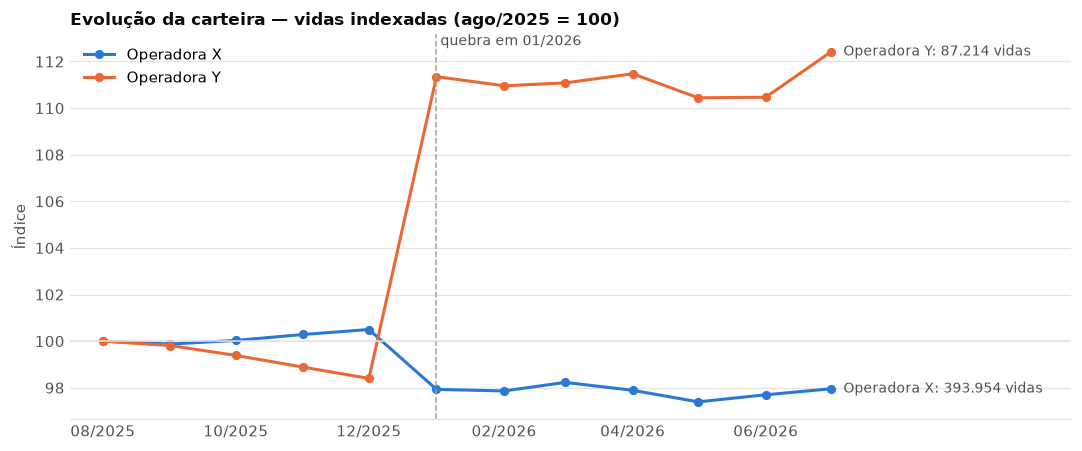

In [5]:
# Vidas indexadas (primeira competência = 100): mesma escala para carteiras de portes distintos.
fig, ax = plt.subplots(figsize=(10, 4.2))
for operadora, grupo in vidas_mes.groupby("Operadora"):
    indice = grupo["vidas"] / grupo["vidas"].iat[0] * 100
    ax.plot(grupo["data_ref"], indice, marker="o", color=CORES_OPERADORA[operadora], label=operadora)
    ax.annotate(
        f"{operadora}: {num(grupo['vidas'].iat[-1])} vidas",
        (grupo["data_ref"].iat[-1], indice.iat[-1]),
        xytext=(8, 0), textcoords="offset points", va="center",
        color=COR_TEXTO_SECUNDARIO, fontsize=9,
    )

salto = pd.to_datetime(evolucao.loc[evolucao["indicador"] == "vidas", "mes_maior_salto"], format="%m/%Y").mode().iat[0]
ax.axvline(salto, color=COR_NEUTRA, linestyle="--", linewidth=1)
ax.text(salto, ax.get_ylim()[1], f" quebra em {mes(salto)}", va="top", color=COR_TEXTO_SECUNDARIO, fontsize=9)
ax.axhline(100, color=COR_GRADE, linewidth=1)
estilizar_eixo(ax, "Evolução da carteira — vidas indexadas (ago/2025 = 100)", "Índice")
ax.legend(loc="upper left")
competencias = sorted(vidas_mes["data_ref"].unique())
ax.set_xticks(competencias[::2], [mes(c) for c in competencias[::2]])
ax.set_xlim(competencias[0] - pd.Timedelta(days=15), competencias[-1] + pd.Timedelta(days=110))
plt.tight_layout()
plt.show()

**Leitura:**

- Ponta a ponta, a X perde 2,05% das vidas e a Y cresce 12,42%. **Os dois movimentos se concentram em uma única competência (jan/2026)**, com saltos de sinal oposto e magnitude quase idêntica (cerca de 10 mil vidas).
- Esse padrão indica uma **mudança de carteira** e não uma tendência comercial gradual. A seção 5 investiga o movimento.
- A receita da Y não acompanha o salto de vidas: a receita por vida cai cerca de 12% em jan/2026. É a primeira evidência de que as vidas que entraram **não têm receita correspondente na base**.

## 3. Despesa líquida estimada e qualidade dos dados financeiros

A despesa líquida é calculada **uma única vez**, no nível do evento, e reutilizada em todo o estudo. Os registros em que a coparticipação supera o valor bruto geram despesa líquida negativa. Eles são **preservados e sinalizados**, nunca excluídos nem truncados, e o efeito deles sobre os indicadores é testado por sensibilidade.

In [6]:
df_despesa["despesa_liquida"] = df_despesa["valor_bruto"] - df_despesa["valor_coparticipacao"]
df_despesa["copart_maior_bruto"] = df_despesa["valor_coparticipacao"] > df_despesa["valor_bruto"]
df_despesa["liquido_negativo"] = df_despesa["despesa_liquida"] < 0

# Por definição, coparticipação > bruto é exatamente o conjunto de líquidos negativos.
assert df_despesa["copart_maior_bruto"].equals(df_despesa["liquido_negativo"])

despesa_liquida_mes = (
    df_despesa.groupby(CHAVES_MES, as_index=False)
    .agg(
        despesa_bruta=("valor_bruto", "sum"),
        coparticipacao=("valor_coparticipacao", "sum"),
        despesa_liquida=("despesa_liquida", "sum"),
        registros=("despesa_liquida", "size"),
        registros_liquidos_negativos=("liquido_negativo", "sum"),
    )
    .sort_values(CHAVES_MES)
)

# Reconciliação: a agregação mensal precisa preservar os totais da base de eventos.
reconciliacao = pd.DataFrame({
    "total_eventos": df_despesa[["valor_bruto", "valor_coparticipacao", "despesa_liquida"]].sum().values,
    "total_mensal": despesa_liquida_mes[["despesa_bruta", "coparticipacao", "despesa_liquida"]].sum().values,
}, index=["despesa_bruta", "coparticipacao", "despesa_liquida"])
reconciliacao["diferenca"] = reconciliacao["total_mensal"] - reconciliacao["total_eventos"]
display(reconciliacao)
assert reconciliacao["diferenca"].abs().max() < 0.01, "Totais alterados na agregação."
assert despesa_liquida_mes.groupby("Operadora")["data_ref"].nunique().eq(12).all()

display(para_exibicao(despesa_liquida_mes))

,total_eventos,total_mensal,diferenca
despesa_bruta,"983,857,641.28","983,857,641.27",-0.00
coparticipacao,"132,075,337.59","132,075,337.59",0.00
despesa_liquida,"851,782,303.68","851,782,303.68",0.00


,Operadora,data_ref,despesa_bruta,coparticipacao,despesa_liquida,registros,registros_liquidos_negativos
0,Operadora X,2025-08-01,"63,113,082.96","8,850,480.56","54,262,602.40",361813,2246
1,Operadora X,2025-09-01,"56,649,074.75","8,158,363.06","48,490,711.69",334023,2018
2,Operadora X,2025-10-01,"57,323,615.98","8,162,132.01","49,161,483.97",352162,1866
3,Operadora X,2025-11-01,"50,584,000.29","7,570,186.78","43,013,813.52",318354,1862
4,Operadora X,2025-12-01,"54,299,657.12","7,113,954.99","47,185,702.14",310332,1679
5,Operadora X,2026-01-01,"54,321,400.45","7,892,977.26","46,428,423.18",310887,1879
6,Operadora X,2026-02-01,"49,523,995.34","6,682,606.23","42,841,389.11",287325,1788
7,Operadora X,2026-03-01,"61,816,948.09","8,234,682.54","53,582,265.56",351810,1546
8,Operadora X,2026-04-01,"57,066,666.82","7,898,316.84","49,168,349.97",332128,1638
9,Operadora X,2026-05-01,"58,509,884.89","7,111,622.58","51,398,262.31",345517,816


In [7]:
# Impacto financeiro dos registros com coparticipação superior ao valor bruto.
ocorrencia = df_despesa["copart_maior_bruto"]
base_qualidade = pd.DataFrame({
    "Operadora": df_despesa["Operadora"],
    "ocorrencia": ocorrencia,
    "liquido_negativo": df_despesa["liquido_negativo"],
    "valor_bruto": df_despesa["valor_bruto"],
    "valor_coparticipacao": df_despesa["valor_coparticipacao"],
    "despesa_liquida": df_despesa["despesa_liquida"],
    "bruto_ocorrencia": df_despesa["valor_bruto"].where(ocorrencia),
    "copart_ocorrencia": df_despesa["valor_coparticipacao"].where(ocorrencia),
    "saldo_ocorrencia": df_despesa["despesa_liquida"].where(ocorrencia),
})


def somar_preservando_nan(serie: pd.Series) -> float:
    return serie.sum(min_count=1)


impacto_coparticipacao = (
    base_qualidade.groupby("Operadora", as_index=False)
    .agg(
        registros=("ocorrencia", "size"),
        ocorrencias=("ocorrencia", "sum"),
        valor_bruto_nas_ocorrencias=("bruto_ocorrencia", somar_preservando_nan),
        coparticipacao_nas_ocorrencias=("copart_ocorrencia", somar_preservando_nan),
        saldo_estimado_nas_ocorrencias=("saldo_ocorrencia", somar_preservando_nan),
        despesa_bruta_total=("valor_bruto", "sum"),
        coparticipacao_total=("valor_coparticipacao", "sum"),
        despesa_liquida_estimada_total=("despesa_liquida", "sum"),
        registros_liquidos_negativos=("liquido_negativo", "sum"),
    )
)
impacto_coparticipacao["percentual_ocorrencias"] = (
    impacto_coparticipacao["ocorrencias"] / impacto_coparticipacao["registros"] * 100
)
display(para_exibicao(impacto_coparticipacao))

,Operadora,registros,ocorrencias,valor_bruto_nas_ocorrencias,coparticipacao_nas_ocorrencias,saldo_estimado_nas_ocorrencias,despesa_bruta_total,coparticipacao_total,despesa_liquida_estimada_total,registros_liquidos_negativos,percentual_ocorrencias
0,Operadora X,3985249,21188,"5,812,099.19","10,868,465.80","-5,056,366.61","689,565,995.16","96,409,469.03","593,156,526.13",21188,0.53
1,Operadora Y,1009982,1157,"316,682.02","956,384.88","-639,702.86","294,291,646.12","35,665,868.56","258,625,777.55",1157,0.11


In [8]:
# Painel de sinais de qualidade por operadora (diagnóstico; nada é corrigido).
sinais = df_despesa.assign(
    frequencia_fracionaria=(df_despesa["frequencia"] % 1) != 0,
    copart_zero=df_despesa["valor_coparticipacao"] == 0,
    bruto_zero=df_despesa["valor_bruto"] == 0,
    bruto_nao_identificado=df_despesa["valor_bruto"].where(df_despesa["classificacao"] == "N/I", 0),
)
painel_sinais = sinais.groupby("Operadora").agg(
    registros=("valor_bruto", "size"),
    copart_maior_bruto=("copart_maior_bruto", "sum"),
    bruto_zero=("bruto_zero", "sum"),
    copart_zero=("copart_zero", "sum"),
    frequencia_fracionaria=("frequencia_fracionaria", "sum"),
    despesa_bruta=("valor_bruto", "sum"),
    coparticipacao=("valor_coparticipacao", "sum"),
    despesa_nao_identificada=("bruto_nao_identificado", "sum"),
)
painel_sinais_pct = pd.DataFrame({
    "copart_maior_bruto_%_registros": painel_sinais["copart_maior_bruto"] / painel_sinais["registros"] * 100,
    "copart_zero_%_registros": painel_sinais["copart_zero"] / painel_sinais["registros"] * 100,
    "frequencia_fracionaria_%_registros": painel_sinais["frequencia_fracionaria"] / painel_sinais["registros"] * 100,
    "coparticipacao_%_despesa_bruta": painel_sinais["coparticipacao"] / painel_sinais["despesa_bruta"] * 100,
    "classificacao_N/I_%_despesa_bruta": painel_sinais["despesa_nao_identificada"] / painel_sinais["despesa_bruta"] * 100,
    "registros_bruto_zero": painel_sinais["bruto_zero"],
})
display(para_exibicao(painel_sinais_pct))
del sinais

,copart_maior_bruto_%_registros,copart_zero_%_registros,frequencia_fracionaria_%_registros,coparticipacao_%_despesa_bruta,classificacao_N/I_%_despesa_bruta,registros_bruto_zero
Operadora,,,,,,
Operadora X,0.53,6.10,0.05,13.98,1.17,22
Operadora Y,0.11,27.69,0.06,12.12,1.51,0


**Leitura:**

- **Coparticipação maior que o valor bruto:** 22.345 registros (0,53% dos eventos da X e 0,11% da Y), concentrados em consultas, exames e terapias. A taxa na X é cerca de 5× a da Y, o que indica regra de lançamento (estornos, coparticipação agregada, teto) e não erro aleatório.
- **Materialidade:** o saldo negativo desses registros reduz a despesa líquida em 0,85% (X) e 0,25% (Y). A sensibilidade da seção 4 mostra que o efeito sobre a sinistralidade é **imaterial**.
- **Coparticipação zerada:** 27,7% dos eventos da Y não têm coparticipação, contra 6,1% na X. É uma diferença de desenho de produto ou de regra de cobrança. Ainda assim, o peso da coparticipação sobre a despesa bruta é semelhante (14,0% na X e 12,1% na Y).
- **Frequência e classificação "N/I":** apenas 0,05% dos eventos têm frequência fracionária, o que permite usar a frequência como *proxy* de utilização (seção 6). A classificação "N/I" responde por cerca de 1,2% (X) e 1,5% (Y) da despesa bruta: é despesa sem classificação assistencial e, portanto, sem gestão possível.

## 4. Indicadores solicitados — sinistralidade, ROI e custo per capita

Despesas, vidas e receita são integradas no nível **operadora × competência**, com `validate="one_to_one"` para impedir multiplicação de valores. Indicadores do período usam **razão de totais**, nunca a média de razões mensais.

In [9]:
def calcular_indicadores_mensais(despesa: pd.DataFrame, vidas: pd.DataFrame, receita: pd.DataFrame) -> pd.DataFrame:
    """Integra as três fontes por operadora e mês e calcula os indicadores mensais."""
    base = (
        despesa
        .merge(vidas, on=CHAVES_MES, how="left", validate="one_to_one", indicator="merge_vidas")
        .merge(receita, on=CHAVES_MES, how="left", validate="one_to_one", indicator="merge_receita")
    )
    if not base["merge_vidas"].eq("both").all():
        raise ValueError("Há competências de despesa sem vidas correspondentes.")

    base["sinistralidade_pct"] = dividir_seguro(base["despesa_liquida"], base["receita"]) * 100
    base["roi_pct"] = dividir_seguro(base["receita"] - base["despesa_liquida"], base["despesa_liquida"]) * 100
    base["custo_per_capita_mensal"] = dividir_seguro(base["despesa_liquida"], base["vidas"])
    return base


def consolidar_periodo(base: pd.DataFrame) -> pd.DataFrame:
    """Indicadores do período por razão de totais; receita parcial ou ausente gera NaN."""
    resumo = (
        base.groupby("Operadora", as_index=False)
        .agg(
            receita_total=("receita", lambda serie: serie.sum(min_count=1)),
            despesa_liquida_total=("despesa_liquida", "sum"),
            media_despesa_liquida=("despesa_liquida", "mean"),
            media_vidas=("vidas", "mean"),
            meses_com_receita=("receita", "count"),
            meses_analisados=("data_ref", "nunique"),
        )
    )
    resumo["cobertura_receita_completa"] = (
        resumo["meses_com_receita"].eq(resumo["meses_analisados"]) & resumo["meses_analisados"].gt(0)
    )
    receita_valida = resumo["receita_total"].where(resumo["cobertura_receita_completa"])
    despesa = resumo["despesa_liquida_total"]

    resumo["sinistralidade_pct"] = dividir_seguro(despesa, receita_valida) * 100
    resumo["roi_pct"] = dividir_seguro(receita_valida - despesa, despesa) * 100
    # Média da despesa ÷ média de vidas = Σ despesa ÷ Σ vidas-mês (exposição ponderada).
    resumo["custo_per_capita"] = dividir_seguro(resumo["media_despesa_liquida"], resumo["media_vidas"])
    resumo["status_receita"] = np.select(
        [resumo["meses_com_receita"].eq(0), resumo["cobertura_receita_completa"]],
        ["Ausente na base fornecida", "Completa no período"],
        default="Cobertura parcial — indicador do período indisponível",
    )
    return resumo


base_indicadores = calcular_indicadores_mensais(despesa_liquida_mes, vidas_mes, receita_mes)
resumo_periodo = consolidar_periodo(base_indicadores)

display(
    base_indicadores[["merge_vidas", "merge_receita"]]
    .apply(lambda coluna: coluna.value_counts())
    .rename_axis("correspondencia")
)

# Prova de consistência do per capita: média/média == soma/soma.
per_capita_somas = (
    base_indicadores.groupby("Operadora")["despesa_liquida"].sum()
    / base_indicadores.groupby("Operadora")["vidas"].sum()
)
assert np.allclose(resumo_periodo.set_index("Operadora")["custo_per_capita"], per_capita_somas)

print("Indicadores consolidados do período:")
display(para_exibicao(resumo_periodo))

,merge_vidas,merge_receita
correspondencia,,
left_only,0,12
right_only,0,0
both,24,12


Indicadores consolidados do período:


,Operadora,receita_total,despesa_liquida_total,media_despesa_liquida,media_vidas,meses_com_receita,meses_analisados,cobertura_receita_completa,sinistralidade_pct,roi_pct,custo_per_capita,status_receita
0,Operadora X,NaN,"593,156,526.13","49,429,710.51","397,367.50",0,12,False,NaN,NaN,124.39,Ausente na base fornecida
1,Operadora Y,"757,259,505.37","258,625,777.55","21,552,148.13","82,404.83",12,12,True,34.15,192.80,261.54,Completa no período


In [10]:
# Por que a média simples de razões mensais NÃO deve ser usada (inclusive no Power BI).
comparacao_agregacao = pd.DataFrame({
    "custo_per_capita_razao_de_totais": resumo_periodo.set_index("Operadora")["custo_per_capita"],
    "custo_per_capita_media_simples": base_indicadores.groupby("Operadora")["custo_per_capita_mensal"].mean(),
    "sinistralidade_razao_de_totais": resumo_periodo.set_index("Operadora")["sinistralidade_pct"],
    "sinistralidade_media_simples": base_indicadores.groupby("Operadora")["sinistralidade_pct"].mean(),
})
display(para_exibicao(comparacao_agregacao))

# Armadilha do total geral: somar despesa de X e Y contra receita apenas de Y.
sinistralidade_total_ingenua = (
    base_indicadores["despesa_liquida"].sum() / base_indicadores["receita"].sum() * 100
)
sinistralidade_total_correta = (
    base_indicadores.loc[base_indicadores["receita"].notna(), "despesa_liquida"].sum()
    / base_indicadores["receita"].sum() * 100
)
print(f"Sinistralidade 'total geral' ingênua (X+Y ÷ receita Y): {pct(sinistralidade_total_ingenua)}  <- ERRADA")
print(f"Sinistralidade total restrita a linhas com receita:     {pct(sinistralidade_total_correta)}")

,custo_per_capita_razao_de_totais,custo_per_capita_media_simples,sinistralidade_razao_de_totais,sinistralidade_media_simples
Operadora,,,,
Operadora X,124.39,124.44,NaN,NaN
Operadora Y,261.54,262.84,34.15,34.22


Sinistralidade 'total geral' ingênua (X+Y ÷ receita Y): 112,48%  <- ERRADA
Sinistralidade total restrita a linhas com receita:     34,15%


In [11]:
# Sensibilidade: e se os líquidos negativos fossem truncados em zero?
sensibilidade = impacto_coparticipacao.set_index("Operadora")[
    ["despesa_liquida_estimada_total", "saldo_estimado_nas_ocorrencias"]
].copy()
sensibilidade["despesa_liquida_truncada"] = (
    sensibilidade["despesa_liquida_estimada_total"] - sensibilidade["saldo_estimado_nas_ocorrencias"]
)
sensibilidade["efeito_truncamento_pct"] = variacao_pct(
    sensibilidade["despesa_liquida_estimada_total"], sensibilidade["despesa_liquida_truncada"]
)
receita_periodo = resumo_periodo.set_index("Operadora")["receita_total"]
sensibilidade["sinistralidade_atual_pct"] = resumo_periodo.set_index("Operadora")["sinistralidade_pct"]
sensibilidade["sinistralidade_truncada_pct"] = (
    dividir_seguro(sensibilidade["despesa_liquida_truncada"], receita_periodo) * 100
)
display(para_exibicao(sensibilidade))

,despesa_liquida_estimada_total,saldo_estimado_nas_ocorrencias,despesa_liquida_truncada,efeito_truncamento_pct,sinistralidade_atual_pct,sinistralidade_truncada_pct
Operadora,,,,,,
Operadora X,"593,156,526.13","-5,056,366.61","598,212,892.74",0.85,NaN,NaN
Operadora Y,"258,625,777.55","-639,702.86","259,265,480.41",0.25,34.15,34.24


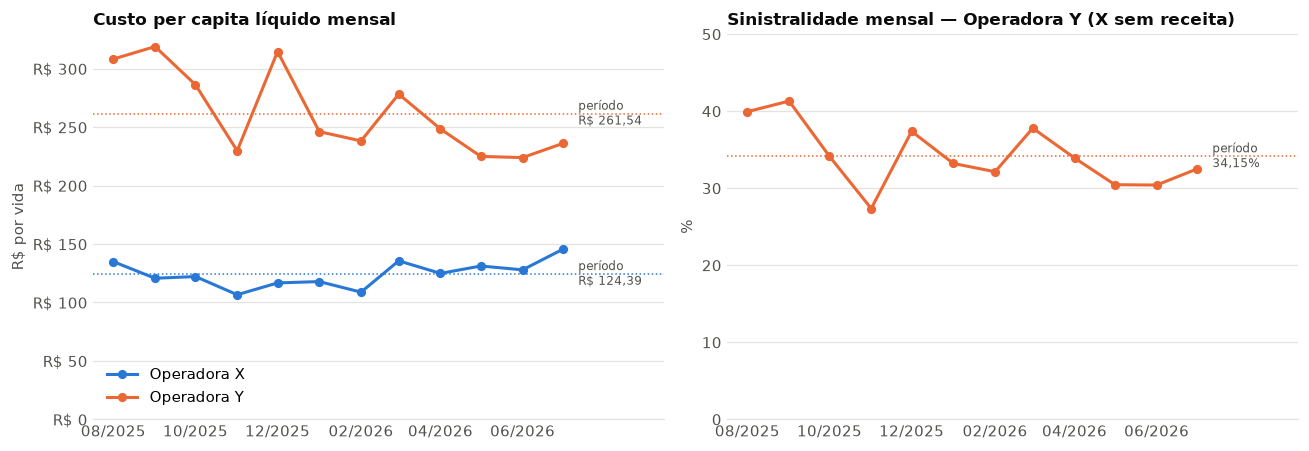

In [12]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 4.2))

for operadora, grupo in base_indicadores.groupby("Operadora"):
    ax1.plot(grupo["data_ref"], grupo["custo_per_capita_mensal"], marker="o",
             color=CORES_OPERADORA[operadora], label=operadora)
    periodo = resumo_periodo.set_index("Operadora").at[operadora, "custo_per_capita"]
    ax1.axhline(periodo, color=CORES_OPERADORA[operadora], linewidth=1, linestyle=":")
    ax1.annotate(f"período\n{brl(periodo)}",(grupo["data_ref"].iat[-1], periodo),
                 xytext=(10, 0), textcoords="offset points", ha="left", va="center",
                 color=COR_TEXTO_SECUNDARIO, fontsize=8)
estilizar_eixo(ax1, "Custo per capita líquido mensal", "R$ por vida")
eixo_reais(ax1)
ax1.set_ylim(bottom=0)
ax1.legend(loc="lower left")

serie_y = base_indicadores.dropna(subset=["sinistralidade_pct"])
for operadora, grupo in serie_y.groupby("Operadora"):
    ax2.plot(grupo["data_ref"], grupo["sinistralidade_pct"], marker="o", color=CORES_OPERADORA[operadora])
    total = resumo_periodo.set_index("Operadora").at[operadora, "sinistralidade_pct"]
    ax2.axhline(total, color=CORES_OPERADORA[operadora], linewidth=1, linestyle=":")
    ax2.annotate(f"período\n{pct(total)}",(grupo["data_ref"].iat[-1], total),
                 xytext=(10, 0), textcoords="offset points", ha="left", va="center",
                 color=COR_TEXTO_SECUNDARIO, fontsize=8)
estilizar_eixo(ax2, "Sinistralidade mensal — Operadora Y (X sem receita)", "%")
ax2.set_ylim(0, 50)

competencias = sorted(base_indicadores["data_ref"].unique())
for ax in (ax1, ax2):
    ax.set_xticks(competencias[::2], [mes(c) for c in competencias[::2]])
    ax.set_xlim(competencias[0] - pd.Timedelta(days=15), competencias[-1] + pd.Timedelta(days=75))
plt.tight_layout()
plt.show()

**Leitura:**

| Indicador | Operadora X | Operadora Y |
|---|---|---|
| Sinistralidade do período | Indisponível (sem receita) | **34,15%** |
| ROI assistencial | Indisponível (sem receita) | **192,80%** |
| Custo per capita líquido (mês) | **R$ 124,39** | **R$ 261,54** |

- **Custo per capita:** a Y custa 2,1× a X por vida/mês. A seção 6 mostra que **o perfil etário explica integralmente essa diferença**: com a pirâmide etária da X, a Y seria mais barata que a X.
- **Sinistralidade de 34% e ROI de 193% são atípicos** para saúde suplementar. Historicamente, a sinistralidade do setor médico-hospitalar fica próxima ou acima de 80% (ANS). O resultado não decorre de erro de fórmula: indica possível **descasamento de escopo entre receita e despesa** (por exemplo, despesa incompleta, receita que inclui outros itens ou diferença de competência). O número não deve ser usado para precificação ou reajuste antes dessa validação.
- **Robustez:** truncar os líquidos negativos em zero altera a sinistralidade da Y de 34,15% para 34,24%. A premissa de despesa líquida não muda nenhuma conclusão.

## 5. ★ Achado estratégico — transferência de carteira em jan/2026

> **Por que isto importa para a diretoria:** a leitura ponta a ponta sugere que a Y cresceu 12,4% e a X encolheu 2,1%. Os dados mostram outra coisa: um **bloco de cerca de 10 mil vidas trocou de operadora em uma única competência**. Esse bloco chegou à Y **sem receita registrada** e deixou na X uma **cauda de despesas** depois da saída. Ignorar o movimento distorce o crescimento, o custo per capita e a sinistralidade.

O diagnóstico abaixo é **orientado por dados**: a competência e os planos são detectados automaticamente pelo maior salto de vidas, sem códigos de plano fixos no código.

In [13]:
LIMIAR_MOVIMENTO_PLANO = 1_000  # vidas: variação mínima para considerar um plano relevante
LIMIAR_ESVAZIAMENTO = 0.05     # plano "esvaziado" quando restam ≤ 5% das vidas

# 5.1 Competência da quebra: maior variação mensal absoluta de vidas, por operadora.
vidas_delta = vidas_mes.assign(variacao=vidas_mes.groupby("Operadora")["vidas"].diff())
quebras = vidas_delta.loc[vidas_delta.groupby("Operadora")["variacao"].apply(lambda s: s.abs().idxmax())]
display(para_exibicao(quebras))

MES_QUEBRA = quebras["data_ref"].mode().iat[0]
MES_ANTERIOR = MES_QUEBRA - pd.DateOffset(months=1)
print(f"Competência da quebra: {mes(MES_QUEBRA)} (comparada a {mes(MES_ANTERIOR)})")

# 5.2 Planos que explicam a quebra.
vidas_plano_mes = df_vidas.groupby(["Operadora", "Plano", "data_ref"], as_index=False)["Vidas"].sum()
matriz_planos = vidas_plano_mes.pivot_table(
    index=["Operadora", "Plano"], columns="data_ref", values="Vidas", aggfunc="sum", fill_value=0
)
movimento = pd.DataFrame({
    "vidas_antes": matriz_planos[MES_ANTERIOR],
    "vidas_depois": matriz_planos[MES_QUEBRA],
})
movimento["variacao"] = movimento["vidas_depois"] - movimento["vidas_antes"]
movimento = movimento[movimento["variacao"].abs() >= LIMIAR_MOVIMENTO_PLANO].reset_index()
movimento["situacao"] = np.select(
    [movimento["vidas_depois"] <= LIMIAR_ESVAZIAMENTO * movimento["vidas_antes"], movimento["vidas_antes"].eq(0)],
    ["Plano esvaziado (≥95% das vidas saem)", "Plano iniciado"],
    default="Variação relevante",
)
uf_principal = (
    df_vidas[df_vidas["Plano"].isin(movimento["Plano"])]
    .groupby(["Plano", "uf"])["Vidas"].sum()
    .groupby(level="Plano").idxmax().str[1]
)
movimento["uf_principal"] = movimento["Plano"].map(uf_principal)
display(movimento)

PLANO_ENCERRADO = movimento.loc[movimento["situacao"].str.startswith("Plano esvaziado")].sort_values("variacao").iloc[0]
PLANO_INICIADO = movimento.loc[movimento["situacao"] == "Plano iniciado"].sort_values("variacao").iloc[-1]

,Operadora,data_ref,vidas,variacao
5,Operadora X,2026-01-01,393846,"-10,338.00"
17,Operadora Y,2026-01-01,86382,"10,046.00"


Competência da quebra: 01/2026 (comparada a 12/2025)


,Operadora,Plano,vidas_antes,vidas_depois,variacao,situacao,uf_principal
0,Operadora X,340154BC84,10110,8,-10102,Plano esvaziado (≥95% das vidas saem),PA
1,Operadora Y,0F2726E6AC,0,10244,10244,Plano iniciado,PA


In [14]:
# 5.3 Os dois planos têm o mesmo perfil etário? (evidência de transferência do mesmo grupo)
def perfil_etario_plano(plano: str, competencia) -> pd.Series:
    filtro = (df_vidas["Plano"] == plano) & (df_vidas["data_ref"] == competencia)
    distribuicao = df_vidas[filtro].groupby("faixa_etaria")["Vidas"].sum()
    return distribuicao / distribuicao.sum() * 100


perfil_migracao = pd.DataFrame({
    f"{PLANO_ENCERRADO['Operadora']} · {PLANO_ENCERRADO['Plano']} ({mes(MES_ANTERIOR)}) %":
        perfil_etario_plano(PLANO_ENCERRADO["Plano"], MES_ANTERIOR),
    f"{PLANO_INICIADO['Operadora']} · {PLANO_INICIADO['Plano']} ({mes(MES_QUEBRA)}) %":
        perfil_etario_plano(PLANO_INICIADO["Plano"], MES_QUEBRA),
}).fillna(0)
SIMILARIDADE_PERFIL = 100 - perfil_migracao.diff(axis=1).iloc[:, -1].abs().sum() / 2
display(para_exibicao(perfil_migracao))
print(f"Similaridade da distribuição etária entre os dois planos: {pct(SIMILARIDADE_PERFIL, 1)}")

,Operadora X · 340154BC84 (12/2025) %,Operadora Y · 0F2726E6AC (01/2026) %
faixa_etaria,,
0 - 18,33.97,33.72
19 - 23,7.81,8.82
24 - 28,4.04,4.06
29 - 33,6.79,6.79
34 - 38,9.77,9.61
39 - 43,10.94,10.89
44 - 48,11.26,11.05
49 - 53,6.94,6.79
54 - 58,4.85,4.71


Similaridade da distribuição etária entre os dois planos: 99,0%


In [15]:
# 5.4 Cobertura de receita: vidas da Y em segmentos sem receita registrada.
cruzamento_receita = df_vidas.merge(
    df_receita[CHAVES_SEGMENTO + ["receita"]],
    on=CHAVES_SEGMENTO, how="outer", validate="one_to_one", indicator=True,
)
operadoras_com_receita = df_receita["Operadora"].unique()
cobertura = cruzamento_receita[cruzamento_receita["Operadora"].isin(operadoras_com_receita)]
receita_sem_vidas = cobertura.loc[cobertura["_merge"] == "right_only", "receita"]
RECEITA_SEM_VIDAS_PCT = receita_sem_vidas.sum() / df_receita["receita"].sum() * 100
print(
    f"Segmentos de receita sem vidas correspondentes: {num(len(receita_sem_vidas))}, somando "
    f"{brl_mi(receita_sem_vidas.sum())} ({pct(RECEITA_SEM_VIDAS_PCT)} da receita do período)."
)

cobertura_receita_mes = (
    cobertura.assign(vidas_sem_receita=cobertura["Vidas"].where(cobertura["receita"].isna(), 0))
    .groupby(CHAVES_MES, as_index=False)
    .agg(vidas=("Vidas", "sum"), vidas_sem_receita=("vidas_sem_receita", "sum"))
)
cobertura_receita_mes["vidas_sem_receita_pct"] = (
    cobertura_receita_mes["vidas_sem_receita"] / cobertura_receita_mes["vidas"] * 100
)
display(para_exibicao(cobertura_receita_mes))

planos_receita = df_receita.groupby(["Operadora", "Plano"])["receita"].sum()
planos_sem_receita = (
    vidas_plano_mes[vidas_plano_mes["Operadora"].isin(operadoras_com_receita)]
    .groupby(["Operadora", "Plano"])["Vidas"].mean()
    .rename("media_vidas_nos_meses_ativos").to_frame()
    .loc[lambda d: ~d.index.isin(planos_receita.index)]
)
print("Planos da operadora com receita que NUNCA aparecem na base de Receita:")
display(para_exibicao(planos_sem_receita))

Segmentos de receita sem vidas correspondentes: 3.788, somando R$ 7,51 mi (0,99% da receita do período).


,Operadora,data_ref,vidas,vidas_sem_receita,vidas_sem_receita_pct
0,Operadora Y,2025-08-01,"77,578.00","1,348.00",1.74
1,Operadora Y,2025-09-01,"77,430.00","1,338.00",1.73
2,Operadora Y,2025-10-01,"77,102.00","1,330.00",1.72
3,Operadora Y,2025-11-01,"76,710.00","1,332.00",1.74
4,Operadora Y,2025-12-01,"76,336.00","1,346.00",1.76
5,Operadora Y,2026-01-01,"86,382.00","11,760.00",13.61
6,Operadora Y,2026-02-01,"86,078.00","11,706.00",13.60
7,Operadora Y,2026-03-01,"86,174.00","11,734.00",13.62
8,Operadora Y,2026-04-01,"86,478.00","11,740.00",13.58
9,Operadora Y,2026-05-01,"85,678.00","11,710.00",13.67


Planos da operadora com receita que NUNCA aparecem na base de Receita:


media_vidas_nos_meses_ativos
Operadora   Plano                                   
Operadora Y 0F2726E6AC                     10,226.00
            7CB52DA0F0                        130.00
            F95F6395A9                         46.29

In [16]:
# 5.5 Despesa líquida mensal dos planos envolvidos: cauda (run-off) e entrada gradual.
planos_migracao = [PLANO_ENCERRADO["Plano"], PLANO_INICIADO["Plano"]]
despesa_plano_mes = (
    df_despesa[df_despesa["Plano"].isin(planos_migracao)]
    .groupby(["Operadora", "Plano", "data_ref"], as_index=False)["despesa_liquida"].sum()
)
painel_migracao = (
    vidas_plano_mes[vidas_plano_mes["Plano"].isin(planos_migracao)]
    .merge(despesa_plano_mes, on=["Operadora", "Plano", "data_ref"], how="outer")
    .fillna({"Vidas": 0, "despesa_liquida": 0})
    .sort_values(["Operadora", "data_ref"])
)
display(para_exibicao(painel_migracao.pivot_table(
    index="data_ref", columns=["Operadora", "Plano"], values=["Vidas", "despesa_liquida"], aggfunc="sum"
)))

cauda = painel_migracao[
    (painel_migracao["Plano"] == PLANO_ENCERRADO["Plano"]) & (painel_migracao["data_ref"] >= MES_QUEBRA)
]
DESPESA_CAUDA = cauda["despesa_liquida"].sum()
VIDAS_CAUDA = cauda["Vidas"].sum()
print(
    f"Despesa líquida do plano esvaziado a partir de {mes(MES_QUEBRA)}: {brl_mi(DESPESA_CAUDA)} "
    f"com {num(VIDAS_CAUDA)} vidas expostas no mesmo intervalo."
)

Vidas             despesa_liquida            
Operadora  Operadora X Operadora Y     Operadora X Operadora Y
Plano       340154BC84  0F2726E6AC      340154BC84  0F2726E6AC
data_ref                                                      
2025-08-01   10,282.00         NaN      463,145.80         NaN
2025-09-01   10,260.00         NaN      315,389.34         NaN
2025-10-01   10,214.00         NaN      402,944.00         NaN
2025-11-01   10,176.00         NaN      319,581.90         NaN
2025-12-01   10,110.00         NaN      363,073.00         NaN
2026-01-01        8.00   10,244.00      342,825.14        0.00
2026-02-01        8.00   10,214.00      210,672.45       90.04
2026-03-01        8.00   10,248.00      220,488.04   71,237.62
2026-04-01        8.00   10,240.00       31,588.84  215,819.28
2026-05-01        8.00   10,224.00       96,770.42  392,618.74
2026-06-01        8.00   10,128.00       14,286.80  461,453.08
2026-07-01        8.00   10,284.00       37,295.41  417,511.61

Despesa líquida do plano esvaziado a partir de 01/2026: R$ 0,95 mi com 56 vidas expostas no mesmo intervalo.


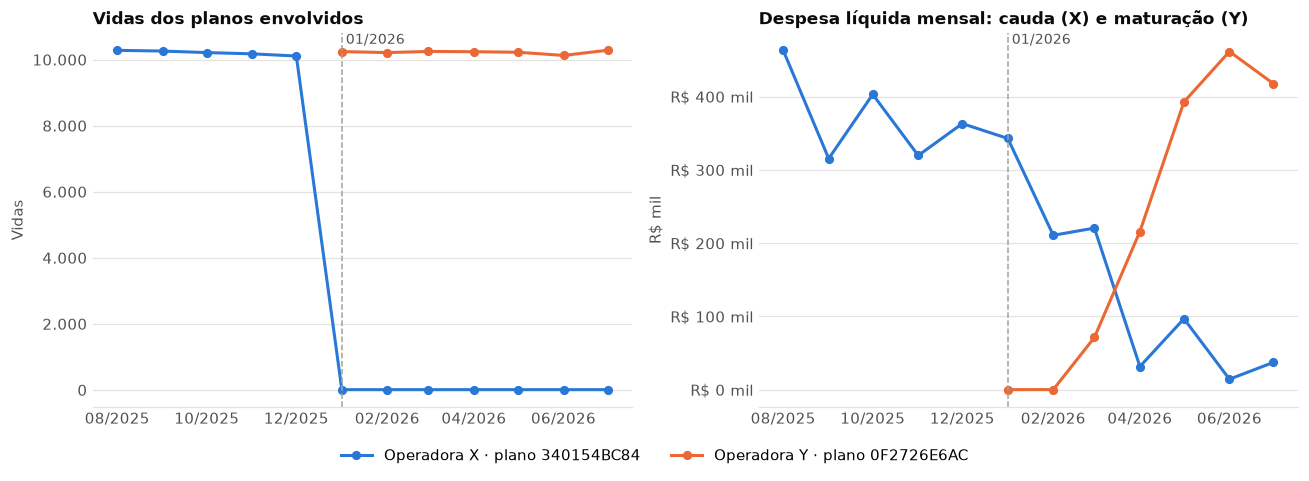

In [17]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 4.4))
for _, plano in pd.DataFrame([PLANO_ENCERRADO, PLANO_INICIADO]).iterrows():
    serie = painel_migracao[painel_migracao["Plano"] == plano["Plano"]]
    cor = CORES_OPERADORA[plano["Operadora"]]
    rotulo = f"{plano['Operadora']} · plano {plano['Plano']}"
    ax1.plot(serie["data_ref"], serie["Vidas"], marker="o", color=cor, label=rotulo)
    ax2.plot(serie["data_ref"], serie["despesa_liquida"], marker="o", color=cor, label=rotulo)

for ax in (ax1, ax2):
    ax.axvline(MES_QUEBRA, color=COR_NEUTRA, linestyle="--", linewidth=1)
    ax.text(MES_QUEBRA, ax.get_ylim()[1], f" {mes(MES_QUEBRA)}", va="top", color=COR_TEXTO_SECUNDARIO, fontsize=9)
    competencias = sorted(painel_migracao["data_ref"].unique())
    ax.set_xticks(competencias[::2], [mes(c) for c in competencias[::2]])

estilizar_eixo(ax1, "Vidas dos planos envolvidos", "Vidas")
ax1.yaxis.set_major_formatter(mticker.FuncFormatter(lambda v, _: num(v)))
estilizar_eixo(ax2, "Despesa líquida mensal: cauda (X) e maturação (Y)", "R$ mil")
eixo_reais(ax2, escala=1_000, sufixo=" mil")
fig.legend(*ax1.get_legend_handles_labels(), loc="lower center", ncol=2, bbox_to_anchor=(0.5, 0))
plt.tight_layout(rect=(0, 0.07, 1, 1))
plt.show()

In [18]:
# 5.6 Indicadores da Y com e sem o efeito da migração.
operadora_receptora = PLANO_INICIADO["Operadora"]
chaves_plano = ["Operadora", "Plano", "data_ref"]

base_plano = (
    vidas_plano_mes.rename(columns={"Vidas": "vidas"})
    .merge(df_despesa.groupby(chaves_plano, as_index=False)["despesa_liquida"].sum(), on=chaves_plano, how="outer")
    .merge(df_receita.groupby(chaves_plano, as_index=False)["receita"].sum(), on=chaves_plano, how="left")
    .query("Operadora == @operadora_receptora")
    .fillna({"vidas": 0, "despesa_liquida": 0})
)
assert np.isclose(
    base_plano["despesa_liquida"].sum(),
    resumo_periodo.set_index("Operadora").at[operadora_receptora, "despesa_liquida_total"],
)


def indicadores_recorte(df: pd.DataFrame, nome: str) -> dict:
    receita, despesa = df["receita"].sum(), df["despesa_liquida"].sum()
    return {
        "recorte": nome,
        "receita": receita,
        "despesa_liquida": despesa,
        "media_vidas": df.groupby("data_ref")["vidas"].sum().reindex(sorted(df_vidas["data_ref"].unique()), fill_value=0).mean(),
        "sinistralidade_pct": dividir_seguro(despesa, receita) * 100,
        "custo_per_capita": dividir_seguro(despesa, df["vidas"].sum()),
    }


recortes_y = pd.DataFrame([
    indicadores_recorte(base_plano, "Oficial — todos os planos"),
    indicadores_recorte(base_plano[base_plano["receita"].gt(0)], "Somente planos-competência com receita"),
    indicadores_recorte(base_plano[base_plano["Plano"] != PLANO_INICIADO["Plano"]], "Sem o plano transferido"),
])
display(para_exibicao(recortes_y))

# Crescimento orgânico: variação de vidas excluindo os planos envolvidos na transferência.
crescimento = []
for operadora, grupo in vidas_plano_mes.groupby("Operadora"):
    sem_migracao = grupo[~grupo["Plano"].isin(planos_migracao)].groupby("data_ref")["Vidas"].sum()
    total = grupo.groupby("data_ref")["Vidas"].sum()
    crescimento.append({
        "Operadora": operadora,
        "variacao_total_pct": variacao_pct(total.iat[0], total.iat[-1]),
        "variacao_organica_pct": variacao_pct(sem_migracao.iat[0], sem_migracao.iat[-1]),
    })
crescimento = pd.DataFrame(crescimento)
display(para_exibicao(crescimento))

,recorte,receita,despesa_liquida,media_vidas,sinistralidade_pct,custo_per_capita
0,Oficial — todos os planos,"757,259,505.38","258,625,777.55","82,404.83",34.15,261.54
1,Somente planos-competência com receita,"757,259,505.38","256,981,184.52","76,336.83",33.94,280.53
2,Sem o plano transferido,"757,259,505.38","257,067,047.20","76,439.67",33.95,280.25


,Operadora,variacao_total_pct,variacao_organica_pct
0,Operadora X,-2.05,0.52
1,Operadora Y,12.42,-0.84


### 5.7 Diagnóstico da transferência — Evidência → Risco → Recomendação


| Dimensão | Evidência | Risco | Recomendação |
|---|---|---|---|
| **Carteira** | O plano `340154BC84` (X, PA) cai de 10.110 para 8 vidas, e o plano `0F2726E6AC` (Y, PA) passa de 0 para 10.244 vidas na mesma competência, com distribuição etária 99,0% semelhante. | O crescimento da Y (+12,42%) e a retração da X (−2,05%) são **inorgânicos**: sem o bloco, X +0,52% e Y −0,84%. A Y, na prática, **perdeu vidas organicamente**. | Separar crescimento orgânico e inorgânico no dashboard e na comunicação à diretoria; investigar a evasão orgânica da Y. |
| **Receita** | O plano transferido não tem nenhuma linha na base de Receita. As vidas da Y sem receita passam de 1,8% para 13,6%, e a receita por vida da Y cai cerca de 12% em jan/2026. Há também 3.788 segmentos de receita sem vidas correspondentes (0,99% da receita). | A sinistralidade e a receita por vida da Y misturam vidas com e sem receita. Precificação e reajuste baseados nesses números ficam enviesados. | Obter a receita do plano `0F2726E6AC` e reconciliar receita × vidas por segmento. |
| **Sinistro (cauda e maturação)** | A X registra R$ 0,95 mi de despesa líquida no plano após a saída, com apenas 8 vidas. Na Y, a despesa do plano começa em zero e só atinge o patamar histórico (cerca de R$ 0,4 mi/mês) a partir de mai/2026. | **Despesa sem exposição** na X (cauda/IBNR) e **subnotificação temporária** na Y por atraso de aviso. Nos primeiros meses, o plano parece "barato". | Provisionar IBNR para a cauda da X, acompanhar a curva de maturação do plano na Y e não usar os primeiros meses do plano como base de precificação. |
| **Indicadores da Y** | Sem o plano transferido: sinistralidade de 33,95% (vs. 34,15%) e custo per capita de R$ 280,25 (vs. R$ 261,54). | O bloco novo, com sinistros ainda em maturação, **dilui** o custo per capita da Y: a "melhora" a partir de jan/2026 é efeito de composição, não de gestão. | Acompanhar a Y com e sem o plano até a despesa do bloco maturar. |


**Limitação:** os dados mostram uma transferência compatível em data, porte, UF e perfil etário, mas **não comprovam juridicamente** a operação (portabilidade, cessão de carteira ou migração de contrato empresarial). A confirmação depende de informação contratual fora destas bases.

## 6. Perfil da carteira e das despesas

Distribuição de vidas e despesas por faixa etária e por classificação assistencial. A granularidade **operadora × competência × faixa etária** tem correspondência de 100% entre Despesa e Vidas e é o nível mais detalhado em que despesa por vida pode ser calculada com segurança.

In [19]:
# 6.1 Teste de granularidade: em que nível Despesa e Vidas se correspondem integralmente?
combinacoes_chaves = {
    "Operadora + mês": ["data_ref", "Operadora"],
    "Operadora + mês + faixa etária": ["data_ref", "Operadora", "faixa_etaria"],
    "Operadora + mês + UF": ["data_ref", "Operadora", "uf"],
    "Operadora + mês + plano": ["data_ref", "Operadora", "Plano"],
    "Operadora + mês + plano + faixa etária": ["data_ref", "Operadora", "Plano", "faixa_etaria"],
    "Todas as dimensões": CHAVES_SEGMENTO,
}

resultados_granularidade = []
for nivel, chaves_nivel in combinacoes_chaves.items():
    teste = (
        df_despesa.groupby(chaves_nivel, as_index=False)["valor_bruto"].sum()
        .merge(df_vidas.groupby(chaves_nivel, as_index=False)["Vidas"].sum(),
               on=chaves_nivel, how="outer", validate="one_to_one", indicator=True)
    )
    contagem = teste["_merge"].value_counts()
    resultados_granularidade.append({
        "nivel_analise": nivel,
        "total_segmentos": len(teste),
        "segmentos_em_ambas": int(contagem.get("both", 0)),
        "somente_despesas": int(contagem.get("left_only", 0)),
        "somente_vidas": int(contagem.get("right_only", 0)),
        "cobertura_pct": int(contagem.get("both", 0)) / len(teste) * 100,
    })

display(para_exibicao(pd.DataFrame(resultados_granularidade).sort_values("cobertura_pct", ascending=False)))

,nivel_analise,total_segmentos,segmentos_em_ambas,somente_despesas,somente_vidas,cobertura_pct
0,Operadora + mês,24,24,0,0,100.00
1,Operadora + mês + faixa etária,240,240,0,0,100.00
2,Operadora + mês + UF,574,539,3,32,93.90
3,Operadora + mês + plano,2172,1838,69,265,84.62
4,Operadora + mês + plano + faixa etária,13668,10292,720,2656,75.30
5,Todas as dimensões,232720,111862,16956,103902,48.07


In [20]:
# 6.2 Perfil etário da carteira (média mensal de vidas = exposição média).
vidas_faixa = (
    df_vidas.groupby(["Operadora", "data_ref", "faixa_etaria"], as_index=False)
    .agg(vidas=("Vidas", "sum"))
    .groupby(["Operadora", "faixa_etaria"], as_index=False)
    .agg(media_mensal_vidas=("vidas", "mean"))
)
vidas_faixa["participacao_pct"] = (
    vidas_faixa["media_mensal_vidas"]
    / vidas_faixa.groupby("Operadora")["media_mensal_vidas"].transform("sum") * 100
)
vidas_faixa = vidas_faixa.sort_values(["Operadora", "participacao_pct"], ascending=[True, False])

# 6.3 Despesas e vidas por operadora, competência e faixa etária.
chaves_faixa = ["data_ref", "Operadora", "faixa_etaria"]
analise_faixa = (
    df_despesa.groupby(chaves_faixa, as_index=False)
    .agg(despesa_bruta=("valor_bruto", "sum"), despesa_liquida=("despesa_liquida", "sum"))
    .merge(df_vidas.groupby(chaves_faixa, as_index=False).agg(vidas=("Vidas", "sum")),
           on=chaves_faixa, how="outer", validate="one_to_one", indicator=True)
)
if not analise_faixa["_merge"].eq("both").all():
    raise ValueError("Há segmentos sem correspondência entre Despesa e Vidas por faixa etária.")

perfil_faixa_periodo = (
    analise_faixa.groupby(["Operadora", "faixa_etaria"], as_index=False)
    .agg(
        despesa_bruta_periodo=("despesa_bruta", "sum"),
        media_mensal_vidas=("vidas", "mean"),
        meses_observados=("data_ref", "nunique"),
    )
)
perfil_faixa_periodo["despesa_bruta_media_mensal"] = (
    perfil_faixa_periodo["despesa_bruta_periodo"] / perfil_faixa_periodo["meses_observados"]
)
perfil_faixa_periodo["despesa_bruta_por_vida"] = dividir_seguro(
    perfil_faixa_periodo["despesa_bruta_media_mensal"], perfil_faixa_periodo["media_mensal_vidas"]
)
perfil_faixa_periodo["participacao_vidas_pct"] = (
    perfil_faixa_periodo["media_mensal_vidas"]
    / perfil_faixa_periodo.groupby("Operadora")["media_mensal_vidas"].transform("sum") * 100
)
perfil_faixa_periodo["participacao_despesa_pct"] = (
    perfil_faixa_periodo["despesa_bruta_periodo"]
    / perfil_faixa_periodo.groupby("Operadora")["despesa_bruta_periodo"].transform("sum") * 100
)

# Reconciliação com a base de eventos.
validacao_perfil = perfil_faixa_periodo.groupby("Operadora")["despesa_bruta_periodo"].sum().to_frame("perfil")
validacao_perfil["eventos"] = df_despesa.groupby("Operadora")["valor_bruto"].sum()
validacao_perfil["diferenca"] = validacao_perfil["perfil"] - validacao_perfil["eventos"]
assert validacao_perfil["diferenca"].abs().max() < 0.01
assert perfil_faixa_periodo["meses_observados"].eq(12).all()

display(para_exibicao(perfil_faixa_periodo))

,Operadora,faixa_etaria,despesa_bruta_periodo,media_mensal_vidas,meses_observados,despesa_bruta_media_mensal,despesa_bruta_por_vida,participacao_vidas_pct,participacao_despesa_pct
0,Operadora X,0 - 18,"141,164,723.66","129,240.33",12,"11,763,726.97",91.02,32.52,20.47
1,Operadora X,19 - 23,"29,520,087.17","28,307.00",12,"2,460,007.26",86.90,7.12,4.28
2,Operadora X,24 - 28,"27,037,422.74","17,550.17",12,"2,253,118.56",128.38,4.42,3.92
3,Operadora X,29 - 33,"46,975,266.60","29,533.67",12,"3,914,605.55",132.55,7.43,6.81
4,Operadora X,34 - 38,"74,476,849.56","45,167.83",12,"6,206,404.13",137.41,11.37,10.80
5,Operadora X,39 - 43,"103,122,614.77","53,229.83",12,"8,593,551.23",161.44,13.40,14.95
6,Operadora X,44 - 48,"87,912,055.18","42,625.33",12,"7,326,004.60",171.87,10.73,12.75
7,Operadora X,49 - 53,"55,749,145.75","21,946.67",12,"4,645,762.15",211.68,5.52,8.08
8,Operadora X,54 - 58,"32,866,399.74","11,927.67",12,"2,738,866.65",229.62,3.00,4.77
9,Operadora X,59 e acima,"90,741,429.99","17,839.00",12,"7,561,785.83",423.89,4.49,13.16


In [21]:
# 6.4 Quanto da diferença de custo per capita é explicada pela idade?
# Padronização direta: custo líquido por vida de cada faixa aplicado ao mix etário da outra operadora.
custo_faixa = (
    analise_faixa.groupby(["Operadora", "faixa_etaria"])
    .agg(despesa_liquida=("despesa_liquida", "sum"), vidas_mes=("vidas", "sum"))
)
custo_faixa["custo_por_vida"] = custo_faixa["despesa_liquida"] / custo_faixa["vidas_mes"]
custo_faixa["peso"] = custo_faixa["vidas_mes"] / custo_faixa.groupby(level="Operadora")["vidas_mes"].transform("sum")

custo_x = custo_faixa.loc["Operadora X"]
custo_y = custo_faixa.loc["Operadora Y"]
padronizacao = pd.DataFrame({
    "custo_per_capita_observado": [
        (custo_x["custo_por_vida"] * custo_x["peso"]).sum(),
        (custo_y["custo_por_vida"] * custo_y["peso"]).sum(),
    ],
    "custo_per_capita_com_mix_etario_da_X": [
        (custo_x["custo_por_vida"] * custo_x["peso"]).sum(),
        (custo_y["custo_por_vida"] * custo_x["peso"]).sum(),
    ],
}, index=["Operadora X", "Operadora Y"])
assert np.allclose(padronizacao["custo_per_capita_observado"], resumo_periodo.set_index("Operadora")["custo_per_capita"])

GAP_OBSERVADO = padronizacao.at["Operadora Y", "custo_per_capita_observado"] - padronizacao.at["Operadora X", "custo_per_capita_observado"]
GAP_PADRONIZADO = padronizacao.at["Operadora Y", "custo_per_capita_com_mix_etario_da_X"] - padronizacao.at["Operadora X", "custo_per_capita_observado"]
PARCELA_IDADE = (1.0 - GAP_PADRONIZADO / GAP_OBSERVADO) * 100

display(para_exibicao(padronizacao))
print(f"Diferença observada Y − X: {brl(GAP_OBSERVADO)} por vida/mês")
print(f"Diferença com o mesmo mix etário: {brl(GAP_PADRONIZADO)} por vida/mês")
print(f"Parcela da diferença explicada pela composição etária: {pct(PARCELA_IDADE, 1)}")

custo_faixa_comparado = custo_faixa["custo_por_vida"].unstack("Operadora")
custo_faixa_comparado["razao_Y_sobre_X"] = custo_faixa_comparado["Operadora Y"] / custo_faixa_comparado["Operadora X"]
display(para_exibicao(custo_faixa_comparado))

,custo_per_capita_observado,custo_per_capita_com_mix_etario_da_X
Operadora X,124.39,124.39
Operadora Y,261.54,111.15


Diferença observada Y − X: R$ 137,15 por vida/mês
Diferença com o mesmo mix etário: R$ -13,24 por vida/mês
Parcela da diferença explicada pela composição etária: 109,7%


Operadora,Operadora X,Operadora Y,razao_Y_sobre_X
faixa_etaria,,,
0 - 18,75.32,74.71,0.99
19 - 23,74.78,51.86,0.69
24 - 28,112.37,73.59,0.65
29 - 33,112.62,100.04,0.89
34 - 38,116.35,90.75,0.78
39 - 43,138.67,118.94,0.86
44 - 48,146.39,119.95,0.82
49 - 53,184.33,146.03,0.79
54 - 58,199.57,205.00,1.03


In [22]:
# 6.5 Despesa por classificação assistencial e por regime de atendimento.
despesa_classificacao = (
    df_despesa.groupby(["Operadora", "classificacao"], as_index=False)
    .agg(despesa_bruta=("valor_bruto", "sum"))
)
despesa_classificacao["participacao_pct"] = (
    despesa_classificacao["despesa_bruta"]
    / despesa_classificacao.groupby("Operadora")["despesa_bruta"].transform("sum") * 100
)
despesa_classificacao = despesa_classificacao.sort_values(["Operadora", "despesa_bruta"], ascending=[True, False])
display(para_exibicao(
    despesa_classificacao.pivot(index="classificacao", columns="Operadora", values="participacao_pct")
    .sort_values("Operadora Y", ascending=False)
))

# Utilização: custo por vida = frequência por vida × custo médio por evento.
vidas_mes_total = base_indicadores.groupby("Operadora")["vidas"].sum()
utilizacao = pd.concat([
    df_despesa.groupby(["Operadora", "regime_atendimento"])[["frequencia", "despesa_liquida"]].sum(),
    df_despesa.groupby("Operadora")[["frequencia", "despesa_liquida"]].sum()
    .assign(regime_atendimento="Total").set_index("regime_atendimento", append=True),
]).sort_index()
vidas_linha = utilizacao.index.get_level_values("Operadora").map(vidas_mes_total).to_numpy()
utilizacao["participacao_despesa_pct"] = (
    utilizacao["despesa_liquida"]
    / utilizacao.xs("Total", level="regime_atendimento")["despesa_liquida"]
    .reindex(utilizacao.index.get_level_values("Operadora")).to_numpy() * 100
)
utilizacao["frequencia_por_mil_vidas_mes"] = utilizacao["frequencia"] / vidas_linha * 1_000
utilizacao["custo_medio_por_evento"] = utilizacao["despesa_liquida"] / utilizacao["frequencia"]
utilizacao["custo_por_vida_mes"] = utilizacao["despesa_liquida"] / vidas_linha
display(para_exibicao(utilizacao))

Operadora,Operadora X,Operadora Y
classificacao,,
MEDICAMENTOS,15.55,28.26
PACOTE,16.34,21.42
EXAMES,19.95,13.22
MATERIAIS,10.29,11.44
HONORÁRIOS MÉDICOS,14.85,8.55
DIÁRIAS/ TAXAS,7.13,8.49
CONSULTAS,7.74,3.78
OPME,1.38,1.52
N/I,1.17,1.51


frequencia  despesa_liquida  participacao_despesa_pct  frequencia_por_mil_vidas_mes  custo_medio_por_evento  \
Operadora   regime_atendimento                                                                                                                  
Operadora X Ambulatorial       15,381,078.60   320,549,605.10                     54.04                      3,225.62                   20.84   
            Internação          6,652,331.03   272,606,921.02                     45.96                      1,395.08                   40.98   
            Total              22,033,409.63   593,156,526.13                    100.00                      4,620.70                   26.92   
Operadora Y Ambulatorial        6,069,115.86   112,691,167.34                     43.57                      6,137.50                   18.57   
            Internação          3,702,102.60   145,934,610.21                     56.43                      3,743.82                   39.42   
            Total               9,771,218.46   258,625,777.55                    100.00                      9,881.32                   26.47   

                                custo_por_vida_mes  
Operadora   regime_atendimento                      
Operadora X Ambulatorial                     67.22  
            Internação                       57.17  
            Total                           124.39  
Operadora Y Ambulatorial                    113.96  
            Internação                      147.58  
            Total                           261.54

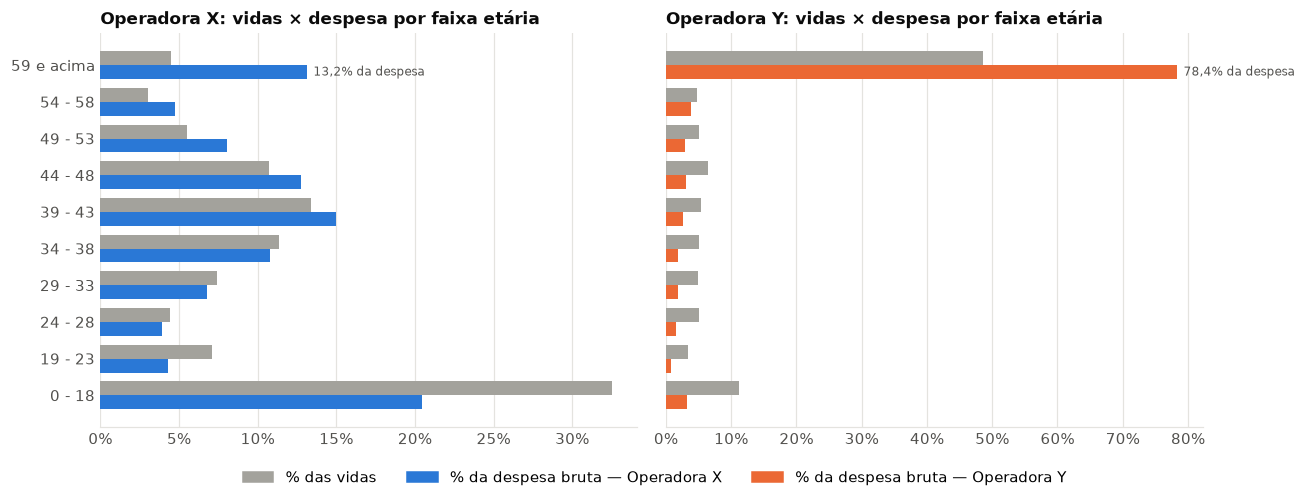

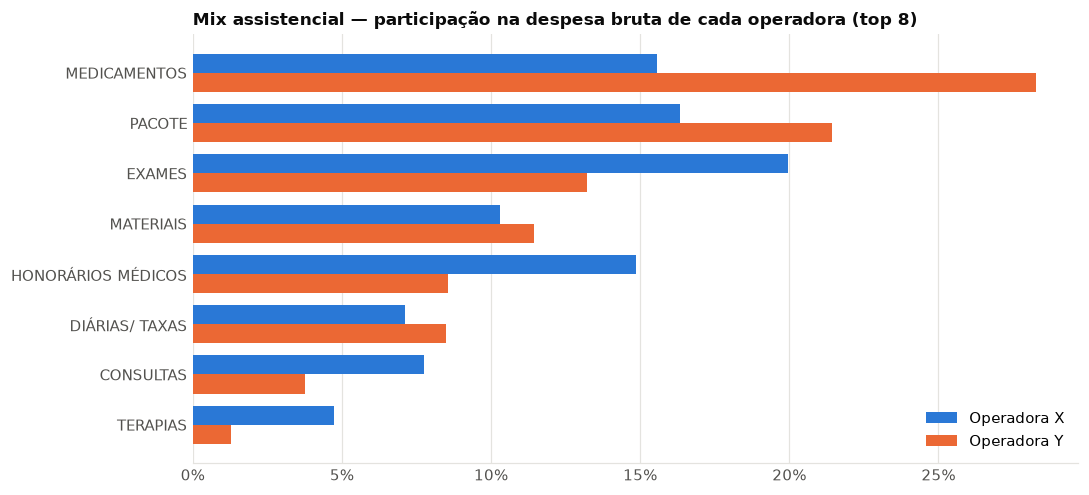

In [23]:
fig, eixos = plt.subplots(1, 2, figsize=(12, 4.6), sharey=True)
faixas = sorted(perfil_faixa_periodo["faixa_etaria"].unique())
posicoes = np.arange(len(faixas))
largura = 0.38
for ax, (operadora, grupo) in zip(eixos, perfil_faixa_periodo.groupby("Operadora")):
    grupo = grupo.set_index("faixa_etaria").reindex(faixas)
    ax.barh(posicoes + largura / 2, grupo["participacao_vidas_pct"], height=largura,
            color=COR_NEUTRA, label="% das vidas")
    ax.barh(posicoes - largura / 2, grupo["participacao_despesa_pct"], height=largura,
            color=CORES_OPERADORA[operadora], label="% da despesa bruta")
    destaque = grupo.loc["59 e acima"]
    ax.annotate(f"{pct(destaque['participacao_despesa_pct'], 1)} da despesa",
                (destaque["participacao_despesa_pct"], faixas.index("59 e acima") - largura / 2),
                xytext=(4, 0), textcoords="offset points", va="center", color=COR_TEXTO_SECUNDARIO, fontsize=8)
    estilizar_eixo(ax, f"{operadora}: vidas × despesa por faixa etária")
    ax.grid(axis="x", color=COR_GRADE, linewidth=0.8)
    ax.grid(axis="y", visible=False)
    ax.xaxis.set_major_formatter(mticker.FuncFormatter(lambda v, _: f"{v:.0f}%"))
eixos[0].set_yticks(posicoes, faixas)
fig.legend(
    handles=[plt.Rectangle((0, 0), 1, 1, color=COR_NEUTRA),
             plt.Rectangle((0, 0), 1, 1, color=CORES_OPERADORA["Operadora X"]),
             plt.Rectangle((0, 0), 1, 1, color=CORES_OPERADORA["Operadora Y"])],
    labels=["% das vidas", "% da despesa bruta — Operadora X", "% da despesa bruta — Operadora Y"],
    loc="lower center", ncol=3, bbox_to_anchor=(0.5, 0),
)
plt.tight_layout(rect=(0, 0.07, 1, 1))
plt.show()

top_classificacoes = (
    despesa_classificacao.groupby("classificacao")["despesa_bruta"].sum().nlargest(8).index
)
tabela = (
    despesa_classificacao[despesa_classificacao["classificacao"].isin(top_classificacoes)]
    .pivot(index="classificacao", columns="Operadora", values="participacao_pct")
    .fillna(0).sort_values("Operadora Y")
)
fig, ax = plt.subplots(figsize=(10, 4.6))
posicoes = np.arange(len(tabela))
for deslocamento, operadora in zip((largura / 2, -largura / 2), tabela.columns):
    ax.barh(posicoes + deslocamento, tabela[operadora], height=largura,
            color=CORES_OPERADORA[operadora], label=operadora)
ax.set_yticks(posicoes, tabela.index)
estilizar_eixo(ax, "Mix assistencial — participação na despesa bruta de cada operadora (top 8)")
ax.grid(axis="x", color=COR_GRADE, linewidth=0.8)
ax.grid(axis="y", visible=False)
ax.xaxis.set_major_formatter(mticker.FuncFormatter(lambda v, _: f"{v:.0f}%"))
ax.legend(loc="lower right")
plt.tight_layout()
plt.show()

### 6.6 Perfil — Evidência → Risco → Recomendação


| Tema | Evidência | Risco | Recomendação |
|---|---|---|---|
| **A idade explica o custo** | Com a pirâmide etária da X, a Y custaria R$ 111,15 por vida/mês, abaixo da X (R$ 124,39). A Y é mais barata que a X em 8 das 10 faixas; só fica mais cara a partir de 54 anos. | Comparar o per capita bruto penaliza a carteira mais velha e **esconde ineficiência na carteira mais jovem**. | KPI padronizado por idade no dashboard. Na X, investigar as faixas de 19 a 53 anos (13% a 53% acima da Y). |
| **Volume, não preço** | O custo médio por item é equivalente (X R$ 26,92; Y R$ 26,47). A diferença de per capita vem da quantidade de itens por vida, 2,1× maior na Y. | A pressão de custo da Y é de **utilização e severidade** (idade); negociar preço com a rede tem efeito limitado. | Na Y, priorizar gestão de cuidado e de utilização (crônicos, internações) em vez de renegociação de preços unitários. |
| **Pirâmide da Y** | A faixa 59+ concentra 48,51% das vidas e 78,39% da despesa bruta, com R$ 480,89 de despesa bruta por vida/mês. A internação responde por 56,43% da despesa líquida. | Concentração de risco: poucos eventos de alto custo movem o resultado, e o envelhecimento é estrutural. | Linhas de cuidado para crônicos, gestão de alto custo e de internações (auditoria concorrente, desospitalização, atenção domiciliar). |
| **Pirâmide da X** | A faixa 0–18 tem 32,52% das vidas e 20,47% da despesa; a faixa 59+ tem 4,49% das vidas e 13,16% da despesa. | Carteira jovem, mas a progressão natural de faixas elevará o custo nos próximos anos. | Monitorar a migração de faixas e o custo das faixas adultas; programas de prevenção. |
| **Mix assistencial** | Y: medicamentos (28,26%) e pacotes (21,42%). X: exames (19,95%) e honorários (14,85%). A classificação "N/I" responde por 1,2% a 1,5% da despesa. | Y: alto custo unitário em medicamentos e hospital. X: alto volume ambulatorial (exames, consultas, terapias). | Y: auditoria de medicamentos e revisão de pacotes. X: protocolos de solicitação de exames e de terapias seriadas. Ambas: reclassificar o "N/I". |


**Limitação:** as participações por faixa e por classificação usam despesa **bruta** para manter o schema publicado no Power BI. A padronização etária (6.4) usa despesa **líquida**, consistente com o custo per capita oficial. Todas as análises são descritivas: associação não implica causalidade.

## 7. Exportação blindada para o Power BI

Antes de gravar qualquer arquivo em `output/`, cada tabela é validada contra o **contrato de dados** e contra a **última versão publicada em `output/`** (os arquivos que o Power BI lê hoje):

1. Nome do arquivo e **ordem exata das colunas** iguais ao `SCHEMA_POWERBI` e à versão publicada.
2. **Tipos após serialização** (como o Power BI lerá o CSV) iguais aos da versão publicada.
3. Mesmo número de linhas e mesmas chaves (operadora, competência, faixa, classificação).

Qualquer divergência interrompe a execução **antes** de sobrescrever os arquivos. A regressão de valores contra a versão publicada é reportada para auditoria. Na primeira execução (sem arquivos em `output/`), apenas o contrato de colunas é validado.

In [24]:
def montar_tabelas_powerbi() -> dict[str, pd.DataFrame]:
    """Monta as tabelas de saída exatamente na ordem de colunas do contrato."""
    indicadores_mensais = base_indicadores.copy()
    indicadores_mensais["data_ref"] = indicadores_mensais["data_ref"].dt.strftime("%Y-%m-%d")
    tabelas = {
        "indicadores_mensais.csv": indicadores_mensais,
        "perfil_carteira_faixa_etaria.csv": vidas_faixa,
        "perfil_despesas_classificacao.csv": despesa_classificacao,
        "qualidade_dados_financeiros.csv": impacto_coparticipacao,
        "indicadores_periodo.csv": resumo_periodo,
        "perfil_despesas_faixa_etaria.csv": perfil_faixa_periodo,
    }
    return {nome: tabela[SCHEMA_POWERBI[nome]].copy() for nome, tabela in tabelas.items()}


def serializar(tabela: pd.DataFrame) -> pd.DataFrame:
    """Simula a leitura do CSV pelo Power BI: grava em memória e relê."""
    buffer = io.StringIO()
    tabela.to_csv(buffer, index=False)
    buffer.seek(0)
    return pd.read_csv(buffer)


def validar_contra_publicado(tabelas: dict[str, pd.DataFrame], pasta_publicada: Path) -> pd.DataFrame:
    """Barreira de contrato: interrompe a exportação se o schema divergir da versão publicada."""
    relatorio = []
    for nome, tabela in tabelas.items():
        esperado = SCHEMA_POWERBI[nome]
        nova = serializar(tabela)
        assert list(nova.columns) == esperado, f"{nome}: colunas novas divergem do contrato."

        caminho_publicado = pasta_publicada / nome
        if not caminho_publicado.exists():
            relatorio.append({"arquivo": nome, "colunas": len(esperado), "linhas": len(nova),
                              "schema_e_tipos": "OK (primeira publicação)",
                              "celulas_numericas_divergentes": 0, "maior_desvio_absoluto": 0.0})
            continue

        publicado = pd.read_csv(caminho_publicado, encoding="utf-8-sig")
        assert list(publicado.columns) == esperado, f"{nome}: versão publicada diverge do contrato."
        tipos_divergentes = {
            coluna: (str(publicado[coluna].dtype), str(nova[coluna].dtype))
            for coluna in esperado if str(publicado[coluna].dtype) != str(nova[coluna].dtype)
        }
        assert not tipos_divergentes, f"{nome}: tipos divergentes {tipos_divergentes}"
        assert len(nova) == len(publicado), f"{nome}: {len(nova)} linhas vs {len(publicado)} publicadas."

        chaves = [c for c in ("Operadora", "data_ref", "faixa_etaria", "classificacao") if c in esperado]
        assert set(nova[chaves].astype(str).itertuples(index=False)) == \
            set(publicado[chaves].astype(str).itertuples(index=False)), f"{nome}: chaves divergentes."

        numericas = publicado.select_dtypes(include="number").columns
        a = nova.sort_values(chaves)[numericas].reset_index(drop=True).to_numpy(dtype=float)
        b = publicado.sort_values(chaves)[numericas].reset_index(drop=True).to_numpy(dtype=float)
        iguais = np.isclose(a, b, rtol=1e-9, atol=1e-6, equal_nan=True)
        relatorio.append({
            "arquivo": nome,
            "colunas": len(esperado),
            "linhas": len(nova),
            "schema_e_tipos": "OK",
            "celulas_numericas_divergentes": int((~iguais).sum()),
            "maior_desvio_absoluto": float(np.nanmax(np.abs(a - b))) if a.size else 0.0,
        })
    return pd.DataFrame(relatorio)


tabelas_exportacao = montar_tabelas_powerbi()
relatorio_contrato = validar_contra_publicado(tabelas_exportacao, PASTA_SAIDA)
display(relatorio_contrato)

,arquivo,colunas,linhas,schema_e_tipos,celulas_numericas_divergentes,maior_desvio_absoluto
0,indicadores_mensais.csv,12,24,OK,0,0.00
1,perfil_carteira_faixa_etaria.csv,4,20,OK,0,0.00
2,perfil_despesas_classificacao.csv,4,34,OK,0,0.00
3,qualidade_dados_financeiros.csv,11,2,OK,0,0.00
4,indicadores_periodo.csv,12,2,OK,0,0.00
5,perfil_despesas_faixa_etaria.csv,9,20,OK,0,0.00


In [25]:
# Somente após todas as barreiras: gravar e reconferir os cabeçalhos gravados.
PASTA_SAIDA.mkdir(exist_ok=True)
for nome, tabela in tabelas_exportacao.items():
    tabela.to_csv(PASTA_SAIDA / nome, index=False, encoding="utf-8-sig")

for nome in tabelas_exportacao:
    gravado = pd.read_csv(PASTA_SAIDA / nome, encoding="utf-8-sig", nrows=0)
    assert list(gravado.columns) == SCHEMA_POWERBI[nome]

print(f"{len(tabelas_exportacao)} arquivos gravados em {PASTA_SAIDA.relative_to(PASTA_RAIZ)}/ — contrato preservado:")
for nome, tabela in tabelas_exportacao.items():
    print(f"  - {nome}: {len(tabela)} linhas × {tabela.shape[1]} colunas")

6 arquivos gravados em output/ — contrato preservado:
  - indicadores_mensais.csv: 24 linhas × 12 colunas
  - perfil_carteira_faixa_etaria.csv: 20 linhas × 4 colunas
  - perfil_despesas_classificacao.csv: 34 linhas × 4 colunas
  - qualidade_dados_financeiros.csv: 2 linhas × 11 colunas
  - indicadores_periodo.csv: 2 linhas × 12 colunas
  - perfil_despesas_faixa_etaria.csv: 20 linhas × 9 colunas


## 8. Síntese executiva gerada a partir dos dados e verificação dos números citados

A síntese abaixo é **gerada pelo código**: cada número vem diretamente das tabelas calculadas. Em seguida, os números citados nos textos fixos deste notebook (resumo executivo e leituras) são conferidos por `assert`.

In [26]:
periodo = resumo_periodo.set_index("Operadora")
vidas_evolucao = evolucao[evolucao["indicador"] == "vidas"].set_index("Operadora")
faixa = perfil_faixa_periodo.set_index(["Operadora", "faixa_etaria"])
mix = despesa_classificacao.set_index(["Operadora", "classificacao"])["participacao_pct"]
cobertura_y = cobertura_receita_mes.set_index(CHAVES_MES)["vidas_sem_receita_pct"]
crescimento_idx = crescimento.set_index("Operadora")
sens = sensibilidade

linhas = [
    "| Tema | Evidência | Risco | Recomendação |",
    "|---|---|---|---|",
    f"| **Transferência de carteira** | Em {mes(MES_QUEBRA)}, o plano {PLANO_ENCERRADO['Plano']} da {PLANO_ENCERRADO['Operadora']} "
    f"({num(PLANO_ENCERRADO['vidas_antes'])} → {num(PLANO_ENCERRADO['vidas_depois'])} vidas, {PLANO_ENCERRADO['uf_principal']}) é esvaziado e o plano {PLANO_INICIADO['Plano']} da "
    f"{PLANO_INICIADO['Operadora']} ({num(PLANO_INICIADO['variacao'])} vidas, {PLANO_INICIADO['uf_principal']}) inicia, com perfil etário "
    f"{pct(SIMILARIDADE_PERFIL, 1)} semelhante. Crescimento orgânico da Y: {pct(crescimento_idx.at['Operadora Y', 'variacao_organica_pct'])} "
    f"(vs. {pct(crescimento_idx.at['Operadora Y', 'variacao_total_pct'])} total). "
    f"| Crescimento superestimado; plano novo sem receita na base; cauda de {brl_mi(DESPESA_CAUDA)} na X após a saída. "
    "| Confirmar a natureza contratual da operação, a responsabilidade pela cauda de sinistros (IBNR) e incluir a receita do plano. |",
    f"| **Custo per capita** | X {brl(periodo.at['Operadora X', 'custo_per_capita'])} vs. Y {brl(periodo.at['Operadora Y', 'custo_per_capita'])} "
    f"por vida/mês; com o mix etário da X, a Y custaria "
    f"{brl(padronizacao.at['Operadora Y', 'custo_per_capita_com_mix_etario_da_X'])} "
    f"({pct(PARCELA_IDADE, 1)} da diferença explicada pela idade). "
    "| Comparar operadoras sem ajuste etário leva a conclusões erradas sobre eficiência. "
    "| Usar custo padronizado por faixa como KPI comparativo no dashboard. |",
    f"| **Concentração 59+ na Y** | {pct(faixa.at[('Operadora Y', '59 e acima'), 'participacao_vidas_pct'])} das vidas e "
    f"{pct(faixa.at[('Operadora Y', '59 e acima'), 'participacao_despesa_pct'])} da despesa bruta. "
    "| Severidade e cronicidade elevadas; sensibilidade a reajuste e a eventos de alto custo. "
    "| Programas de gestão de crônicos, linhas de cuidado e monitoramento de alto custo. |",
    f"| **Mix assistencial da Y** | Medicamentos {pct(mix[('Operadora Y', 'MEDICAMENTOS')])} e pacotes "
    f"{pct(mix[('Operadora Y', 'PACOTE')])} da despesa bruta. "
    "| Exposição a medicamentos de alto custo e a pacotes hospitalares mal precificados. "
    "| Auditoria de medicamentos especiais/oncológicos e renegociação de pacotes. |",
    f"| **Sinistralidade e ROI da Y** | {pct(periodo.at['Operadora Y', 'sinistralidade_pct'])} e "
    f"{pct(periodo.at['Operadora Y', 'roi_pct'])} — muito abaixo do padrão setorial. "
    "| Possível descasamento de escopo entre receita e despesa. "
    "| Validar o escopo antes de usar os números em precificação ou reajuste. |",
    "| **Receita da X** | Ausente em todas as competências. "
    "| Impossível avaliar a sustentabilidade financeira da maior carteira (≈ 4,8× a Y). "
    "| Solicitar a receita da X; até lá, os indicadores ficam indisponíveis, nunca zero. |",
    f"| **Qualidade financeira** | {num(impacto_coparticipacao['ocorrencias'].sum())} eventos com coparticipação > bruto; "
    f"sinistralidade da Y passa de {pct(sens.at['Operadora Y', 'sinistralidade_atual_pct'])} para "
    f"{pct(sens.at['Operadora Y', 'sinistralidade_truncada_pct'])} se truncados. "
    "| Regra de lançamento não documentada. | Auditar a regra de coparticipação e publicar um dicionário de dados. |",
]
display(Markdown("\n".join(linhas)))

| Tema | Evidência | Risco | Recomendação |
|---|---|---|---|
| **Transferência de carteira** | Em 01/2026, o plano 340154BC84 da Operadora X (10.110 → 8 vidas, PA) é esvaziado e o plano 0F2726E6AC da Operadora Y (10.244 vidas, PA) inicia, com perfil etário 99,0% semelhante. Crescimento orgânico da Y: -0,84% (vs. 12,42% total). | Crescimento superestimado; plano novo sem receita na base; cauda de R$ 0,95 mi na X após a saída. | Confirmar a natureza contratual da operação, a responsabilidade pela cauda de sinistros (IBNR) e incluir a receita do plano. |
| **Custo per capita** | X R$ 124,39 vs. Y R$ 261,54 por vida/mês; com o mix etário da X, a Y custaria R$ 111,15 (109,7% da diferença explicada pela idade). | Comparar operadoras sem ajuste etário leva a conclusões erradas sobre eficiência. | Usar custo padronizado por faixa como KPI comparativo no dashboard. |
| **Concentração 59+ na Y** | 48,51% das vidas e 78,39% da despesa bruta. | Severidade e cronicidade elevadas; sensibilidade a reajuste e a eventos de alto custo. | Programas de gestão de crônicos, linhas de cuidado e monitoramento de alto custo. |
| **Mix assistencial da Y** | Medicamentos 28,26% e pacotes 21,42% da despesa bruta. | Exposição a medicamentos de alto custo e a pacotes hospitalares mal precificados. | Auditoria de medicamentos especiais/oncológicos e renegociação de pacotes. |
| **Sinistralidade e ROI da Y** | 34,15% e 192,80% — muito abaixo do padrão setorial. | Possível descasamento de escopo entre receita e despesa. | Validar o escopo antes de usar os números em precificação ou reajuste. |
| **Receita da X** | Ausente em todas as competências. | Impossível avaliar a sustentabilidade financeira da maior carteira (≈ 4,8× a Y). | Solicitar a receita da X; até lá, os indicadores ficam indisponíveis, nunca zero. |
| **Qualidade financeira** | 22.345 eventos com coparticipação > bruto; sinistralidade da Y passa de 34,15% para 34,24% se truncados. | Regra de lançamento não documentada. | Auditar a regra de coparticipação e publicar um dicionário de dados. |

In [27]:
# Números citados nos textos fixos do notebook -> valor recalculado.
NUMEROS_CITADOS = {
    "variação de vidas X (%)": (-2.05, vidas_evolucao.at["Operadora X", "variacao_pct"], 2),
    "variação de vidas Y (%)": (12.42, vidas_evolucao.at["Operadora Y", "variacao_pct"], 2),
    "sinistralidade Y (%)": (34.15, periodo.at["Operadora Y", "sinistralidade_pct"], 2),
    "ROI assistencial Y (%)": (192.80, periodo.at["Operadora Y", "roi_pct"], 2),
    "custo per capita X (R$)": (124.39, periodo.at["Operadora X", "custo_per_capita"], 2),
    "custo per capita Y (R$)": (261.54, periodo.at["Operadora Y", "custo_per_capita"], 2),
    "razão per capita Y/X": (2.1, periodo.at["Operadora Y", "custo_per_capita"] / periodo.at["Operadora X", "custo_per_capita"], 1),
    "sinistralidade Y truncada (%)": (34.24, sens.at["Operadora Y", "sinistralidade_truncada_pct"], 2),
    "sinistralidade total ingênua (%)": (112.48, sinistralidade_total_ingenua, 2),
    "eventos copart > bruto": (22345, impacto_coparticipacao["ocorrencias"].sum(), 0),
    "Y 59+ % vidas": (48.51, faixa.at[("Operadora Y", "59 e acima"), "participacao_vidas_pct"], 2),
    "Y 59+ % despesa": (78.39, faixa.at[("Operadora Y", "59 e acima"), "participacao_despesa_pct"], 2),
    "Y medicamentos %": (28.26, mix[("Operadora Y", "MEDICAMENTOS")], 2),
    "Y pacote %": (21.42, mix[("Operadora Y", "PACOTE")], 2),
    "plano esvaziado — vidas antes": (10110, PLANO_ENCERRADO["vidas_antes"], 0),
    "plano esvaziado — vidas depois": (8, PLANO_ENCERRADO["vidas_depois"], 0),
    "plano iniciado — vidas": (10244, PLANO_INICIADO["variacao"], 0),
    "similaridade etária dos planos (%)": (99.0, SIMILARIDADE_PERFIL, 1),
    "crescimento orgânico X (%)": (0.52, crescimento_idx.at["Operadora X", "variacao_organica_pct"], 2),
    "crescimento orgânico Y (%)": (-0.84, crescimento_idx.at["Operadora Y", "variacao_organica_pct"], 2),
    "vidas Y sem receita antes da quebra (%)": (1.8, cobertura_y.loc[("Operadora Y", MES_ANTERIOR)], 1),
    "vidas Y sem receita na quebra (%)": (13.6, cobertura_y.loc[("Operadora Y", MES_QUEBRA)], 1),
    "queda da receita por vida Y na quebra (%)": (-12, variacao_pct(
        receita_por_vida.set_index(CHAVES_MES).at[("Operadora Y", MES_ANTERIOR), "receita_por_vida"],
        receita_por_vida.set_index(CHAVES_MES).at[("Operadora Y", MES_QUEBRA), "receita_por_vida"]), 0),
    "segmentos de receita sem vidas": (3788, len(receita_sem_vidas), 0),
    "receita sem vidas (% da receita)": (0.99, RECEITA_SEM_VIDAS_PCT, 2),
    "cauda de despesa no plano esvaziado (R$ mi)": (0.95, DESPESA_CAUDA / 1e6, 2),
    "sinistralidade Y sem plano transferido (%)": (33.95, recortes_y.set_index("recorte").at["Sem o plano transferido", "sinistralidade_pct"], 2),
    "per capita Y sem plano transferido (R$)": (280.25, recortes_y.set_index("recorte").at["Sem o plano transferido", "custo_per_capita"], 2),
    "per capita Y com mix etário da X (R$)": (111.15, padronizacao.at["Operadora Y", "custo_per_capita_com_mix_etario_da_X"], 2),
    "parcela da diferença explicada pela idade (%)": (109.7, PARCELA_IDADE, 1),
    "faixas em que Y é mais barata que X": (8, (custo_faixa_comparado["razao_Y_sobre_X"] < 1).sum(), 0),
    "X acima de Y, 19–53 anos — mínimo (%)": (13, ((1 / custo_faixa_comparado.loc["19 - 23":"49 - 53", "razao_Y_sobre_X"]) - 1).min() * 100, 0),
    "X acima de Y, 19–53 anos — máximo (%)": (53, ((1 / custo_faixa_comparado.loc["19 - 23":"49 - 53", "razao_Y_sobre_X"]) - 1).max() * 100, 0),
    "custo médio por item X (R$)": (26.92, utilizacao.at[("Operadora X", "Total"), "custo_medio_por_evento"], 2),
    "custo médio por item Y (R$)": (26.47, utilizacao.at[("Operadora Y", "Total"), "custo_medio_por_evento"], 2),
    "razão de itens por vida Y/X": (2.1, utilizacao.at[("Operadora Y", "Total"), "frequencia_por_mil_vidas_mes"]
        / utilizacao.at[("Operadora X", "Total"), "frequencia_por_mil_vidas_mes"], 1),
    "internação Y (% despesa líquida)": (56.43, utilizacao.at[("Operadora Y", "Internação"), "participacao_despesa_pct"], 2),
    "internação X (% despesa líquida)": (45.96, utilizacao.at[("Operadora X", "Internação"), "participacao_despesa_pct"], 2),
    "Y 59+ despesa bruta por vida (R$)": (480.89, faixa.at[("Operadora Y", "59 e acima"), "despesa_bruta_por_vida"], 2),
    "X 0–18 % vidas": (32.52, faixa.at[("Operadora X", "0 - 18"), "participacao_vidas_pct"], 2),
    "X 0–18 % despesa": (20.47, faixa.at[("Operadora X", "0 - 18"), "participacao_despesa_pct"], 2),
    "X 59+ % vidas": (4.49, faixa.at[("Operadora X", "59 e acima"), "participacao_vidas_pct"], 2),
    "X 59+ % despesa": (13.16, faixa.at[("Operadora X", "59 e acima"), "participacao_despesa_pct"], 2),
    "X medicamentos %": (15.55, mix[("Operadora X", "MEDICAMENTOS")], 2),
    "X pacote %": (16.34, mix[("Operadora X", "PACOTE")], 2),
    "X exames %": (19.95, mix[("Operadora X", "EXAMES")], 2),
    "X honorários %": (14.85, mix[("Operadora X", "HONORÁRIOS MÉDICOS")], 2),
    "porte X/Y (média de vidas)": (4.8, periodo.at["Operadora X", "media_vidas"] / periodo.at["Operadora Y", "media_vidas"], 1),
    "copart zero Y (% eventos)": (27.7, painel_sinais_pct.at["Operadora Y", "copart_zero_%_registros"], 1),
    "copart zero X (% eventos)": (6.1, painel_sinais_pct.at["Operadora X", "copart_zero_%_registros"], 1),
    "frequência fracionária X (% eventos)": (0.05, painel_sinais_pct.at["Operadora X", "frequencia_fracionaria_%_registros"], 2),
    "% eventos copart > bruto X": (0.53, impacto_coparticipacao.set_index("Operadora").at["Operadora X", "percentual_ocorrencias"], 2),
    "% eventos copart > bruto Y": (0.11, impacto_coparticipacao.set_index("Operadora").at["Operadora Y", "percentual_ocorrencias"], 2),
    "efeito do truncamento X (%)": (0.85, sensibilidade.at["Operadora X", "efeito_truncamento_pct"], 2),
    "efeito do truncamento Y (%)": (0.25, sensibilidade.at["Operadora Y", "efeito_truncamento_pct"], 2),
    "taxa copart > bruto X/Y (vezes)": (5, impacto_coparticipacao.set_index("Operadora").at["Operadora X", "percentual_ocorrencias"]
        / impacto_coparticipacao.set_index("Operadora").at["Operadora Y", "percentual_ocorrencias"], 0),
    "coparticipação X (% bruta)": (14.0, painel_sinais_pct.at["Operadora X", "coparticipacao_%_despesa_bruta"], 1),
    "coparticipação Y (% bruta)": (12.1, painel_sinais_pct.at["Operadora Y", "coparticipacao_%_despesa_bruta"], 1),
    "N/I X (% bruta)": (1.2, painel_sinais_pct.at["Operadora X", "classificacao_N/I_%_despesa_bruta"], 1),
    "N/I Y (% bruta)": (1.5, painel_sinais_pct.at["Operadora Y", "classificacao_N/I_%_despesa_bruta"], 1),
}

verificacao = pd.DataFrame(
    [(chave, citado, round(float(calculado), casas)) for chave, (citado, calculado, casas) in NUMEROS_CITADOS.items()],
    columns=["numero_citado", "valor_no_texto", "valor_recalculado"],
)
verificacao["confere"] = np.isclose(verificacao["valor_no_texto"], verificacao["valor_recalculado"])
display(verificacao)
assert verificacao["confere"].all(), "Há números no texto que não conferem com os dados — revisar a narrativa."
print("Todos os números citados no texto conferem com os dados.")

,numero_citado,valor_no_texto,valor_recalculado,confere
0,variação de vidas X (%),-2.05,-2.05,True
1,variação de vidas Y (%),12.42,12.42,True
2,sinistralidade Y (%),34.15,34.15,True
3,ROI assistencial Y (%),192.80,192.80,True
4,custo per capita X (R$),124.39,124.39,True
5,custo per capita Y (R$),261.54,261.54,True
6,razão per capita Y/X,2.10,2.10,True
7,sinistralidade Y truncada (%),34.24,34.24,True
8,sinistralidade total ingênua (%),112.48,112.48,True
9,eventos copart > bruto,"22,345.00","22,345.00",True


Todos os números citados no texto conferem com os dados.


## 9. Recomendações estratégicas priorizadas


### Curto prazo (0–30 dias): governança de dados

1. **Solicitar a receita da Operadora X** e a receita do plano transferido (`0F2726E6AC`). Sem elas, não há avaliação de sustentabilidade da maior carteira.
2. **Confirmar contratualmente a transferência de jan/2026** e definir quem responde pela cauda de sinistros do plano `340154BC84`.
3. **Validar o escopo de receita e de despesa da Y** antes de usar a sinistralidade de 34% em precificação, reajuste ou metas.
4. **Formalizar o dicionário de dados:** despesa líquida, coparticipação e frequência.

### Médio prazo (30–90 dias): inteligência de sinistro

5. **Y:** programa de crônicos e de alto custo para 59+, gestão de internações, auditoria de medicamentos especiais e revisão de pacotes.
6. **X:** investigar utilização e protocolos nas faixas de 19 a 53 anos (exames, consultas e terapias seriadas).
7. **Provisão de IBNR** com curvas de atraso de sinistros por plano, começando pelos planos da transferência.

### Dashboard e próximos passos analíticos

8. Publicar no Power BI o **custo per capita padronizado por idade** e o **crescimento orgânico × inorgânico**.
9. Usar medidas DAX por **razão de totais**, nunca média de razões nem total geral que misture despesa da X com receita da Y.
10. Próximas análises: curva de maturação de sinistros (*lag*), concentração de alto custo (top 1% e 5% dos eventos ou beneficiários, se houver identificador) e cortes por plano e região.


## 10. Limitações

1. **Despesa líquida** é uma estimativa (`bruto − coparticipação`), não uma regra oficial confirmada. A sensibilidade mostra efeito imaterial.
2. **Receita da X** está ausente; sinistralidade e ROI da X não são calculáveis.
3. **Escopo da receita da Y** precisa ser validado: a sinistralidade de 34% é atípica para o setor.
4. **Transferência de carteira** é inferida pelos dados (data, porte, UF e perfil etário), sem documento contratual.
5. **Frequência** é tratada como quantidade de eventos (*proxy* de utilização); 0,05% dos registros têm valor fracionário, sem dicionário que confirme o conceito.
6. **Vidas** representam exposição média mensal, não pessoas únicas.
7. **Causalidade:** diferenças entre operadoras, faixas ou classificações são associações descritivas.

## 11. Reprodutibilidade

- Executar **Kernel → Restart & Run All** a partir da pasta do projeto. Não há caminhos absolutos.
- Os cadernos `01_auditoria_receita`, `02_auditoria_despesa` e `03_auditoria_vidas` documentam a auditoria de cada fonte; este caderno consolida o pipeline.
- As 2 tabelas complementares do PBIP são geradas por `python scripts/gerar_tabelas_complementares_powerbi.py`.
- Fontes esperadas em `data/` (`Receita.csv`, `Vidas.csv`, `Despesa.csv`). Saídas em `output/`, validadas contra a versão já publicada na mesma pasta antes de serem sobrescritas.
- Se o contrato com o Power BI mudar intencionalmente, atualize `SCHEMA_POWERBI` **e** o modelo semântico do PBIP (`dashboard_projeto.SemanticModel`). A barreira da seção 7 impede mudanças acidentais.